# Two small venues — PredictIt's fee arithmetic and thirty-eight years of Iowa

Four venues were surveyed. Two of them are large — Polymarket and Kalshi, with
settled corpora of some 72,000 and 100,000 markets — and they carry the order
books, the open interest and the conflict questions between them, in
[`polymarket.ipynb`](polymarket.ipynb) and [`kalshi.ipynb`](kalshi.ipynb). This one is about the two
that are small, and it takes them together because **what makes each interesting
is the thing the big venues do not have**.

**PredictIt** has 197 markets, all political, and the widest gap between a price
and a probability anywhere in the study — wide enough that the gap is arithmetic
you can compute rather than a bias you have to estimate. It also has the one
result in the literature that nobody has explained: in the only peer-reviewed
cross-venue study of the 2024 election it beat both large venues on calibration,
while being the smallest and the most fee-encumbered of the four.

**The Iowa Electronic Markets** have three open markets and are useless as a
live signal. They have instead a per-day, per-contract record going back to
**1 June 1988** — real money, no trading commission at all, ten presidential
cycles, every question resolved. That is the only place in this study where a
calibration method can be developed against known answers on a file that will
never change, and the only place where a measured longshot bias is a property of
traders rather than of a fee schedule.

**What this notebook does.** It computes, on the corpus already on disk, the
things the research pass established about these two venues:

1. **A price is not a probability, and here the wedge is arithmetic** — the
   profit fee, the withdrawal fee that was removed three days ago, and what the
   pair of them did to the extremes.
2. **The discovery surface is one endpoint and a snapshot**, so there is no
   history unless you record it. The recorder, and what it accumulates into.
3. **The position cap**, which is what stands in for depth on a venue that
   publishes no size at all.
4. **The ladder as a distribution** — PredictIt's eleven-rung seat-count
   markets are a CDF over an ordinal outcome, and they can be judged on
   internal coherence in ways a single market cannot.
5. **The 2024 calibration result**, presented with what it measured and over
   what window, and with a complication the venue's own regulator put in
   writing. The *why* is left open, because it is open.
6. **IEM**: what the archive is, the two corrections without which its prices
   are not probabilities, Brier skill by horizon out past a year, longshot bias
   measured on its own closed corpus rather than quoted, and exclusive-set
   coherence on sixteen years of fee-free Fed-policy contracts.

**What it is not.** No trading advice, no strategy, no claim that anything here
is reachable. Every call is read-only and unauthenticated — no wallet, no key,
no order path — and almost everything is computed from the corpus already on
disk, with at most four live requests, each of which the notebook can do
without. The
cross-venue calibration comparison lives in
[`calibration.ipynb`](calibration.ipynb) and is not repeated here; where this
notebook touches a comparative question it says so and stops.

The facts about access, fees, limits and the literature come from
[`sefer/planning/polymarket-event-probabilities.md`](../../../sefer/planning/polymarket-event-probabilities.md)
and from the module docstrings in [`utils/`](utils/), which carry the
verification state of each figure. Nothing here re-derives them; what it does is
compute their consequences on real markets.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "../" resolves somewhere else entirely and the imports
# below fail with ModuleNotFoundError.
_here = Path.cwd()
_PM = _here if (_here / "utils" / "predictit.py").exists() else _here / "notebooks" / "prediction_markets"
for _path in (str(_PM), str(_PM.parents[1]), str(_PM.parents[2] / "navi")):
    if _path not in sys.path:
        sys.path.insert(0, _path)

import math
import re
import statistics
import textwrap
import time
from collections import Counter, defaultdict
from datetime import date, datetime
from typing import Any, Iterable, Sequence

import numpy
from matplotlib import pyplot
# Matplotlib accepts a datetime on an axis and converts it with this same
# function; calling it here keeps the type checker's account of the call
# honest, since the stubs type these parameters as floats.
from matplotlib.dates import date2num
from numpy.typing import NDArray

from lib import config
from utils import corpus_iem, iem, metrics, predictit

pyplot.style.use(config.glyfish_style)

#: One colour per venue, the same two the other notebooks in this package use,
#: so a figure here sits beside a figure there without re-reading the legend.
PREDICTIT = "#C4005E"
IEM = "#5600C9"
#: Polymarket's colour, used only where a PredictIt number is set against a
#: published Polymarket one. Kalshi does not appear in this notebook.
POLYMARKET = "#0067C4"
GREY = "0.45"


def stamp_source(*names: str, figure: Any = None) -> None:
    """Name the files or calls a figure was drawn from, along its bottom edge.

    The same helper as notebooks/fbi/utils/filing.py and calibration.ipynb,
    restated rather than imported: the FBI copy lives inside that notebook's own
    utils package, and this notebook has no other reason to reach into it.
    """
    figure = figure or pyplot.gcf()
    figure.subplots_adjust(bottom=max(0.12, 0.09 + 0.030 * len(names)))
    figure.text(0.995, 0.005, "\n".join(names), ha="right", va="bottom",
                fontsize=7, family="monospace", alpha=0.65)


#: Live calls are capped and counted. The corpus on disk answers almost every
#: question below; the four live calls exist to show two things a recorded file
#: cannot -- that PredictIt publishes its own rate limit in response headers,
#: and that IEM's month parameter fails silently rather than erroring.
LIVE_BUDGET = 6
_live_calls = 0


def spend(n: int = 1) -> bool:
    """Book `n` live requests against the budget.  False means don't call."""
    global _live_calls
    if _live_calls + n > LIVE_BUDGET:
        return False
    _live_calls += n
    return True


print(f"corpus under {predictit.DATA_DIR}")
print(f"{len(predictit.snapshot_paths())} PredictIt snapshots recorded")
print(f"live budget {LIVE_BUDGET} requests; PredictIt's own ceiling is "
      f"{predictit.RATE_LIMIT_PER_MINUTE}/minute, which the client's RateLimiter enforces "
      f"at {predictit.RateLimiter().per_window}/{predictit.RateLimiter().window:.0f}s")

corpus under /Users/troy/Develop/gly.fish/meida/notebooks/prediction_markets/data
2 PredictIt snapshots recorded
live budget 6 requests; PredictIt's own ceiling is 5/minute, which the client's RateLimiter enforces at 4/62s


## 1. PredictIt is one request

The discovery surface is the whole story of this venue, so it comes first.
There is **one endpoint that returns everything**: `/api/marketdata/all/` serves
every market and every contract in one response — 418 KB when the research pass
measured it live, and the recorded copy below is smaller only because it is
re-serialised without whitespace. There is no
pagination, no cursor, no filter, no search, and no tag vocabulary to curate —
against Polymarket's ≥4,000 dirty tag slugs and keyset walk, PredictIt's
discovery problem does not exist.

The cost of that is the other half of the same fact. One endpoint that returns
the present returns *only* the present. Every contract in the payload reads
`"status": "Open"`; nothing that has closed is served anywhere, so **the venue
publishes no closed corpus at all**. Sections 5 and 9 are about what follows
from that — for the recorder, and for the one measurement this notebook cannot
make on PredictIt and has to make on IEM instead.

The census below is read off the recorded snapshot rather than called, so the
numbers on this page are the ones the file holds.

In [2]:
SNAPSHOTS: list[Path] = predictit.snapshot_paths()
SNAP: dict[str, Any] = predictit.load_snapshot(SNAPSHOTS[-1])
MARKETS: list[dict[str, Any]] = SNAP["markets"]
CONTRACTS: list[dict[str, Any]] = [c for m in MARKETS for c in m["contracts"]]

print(f"snapshot {SNAPSHOTS[-1].name}  captured {SNAP['captured_at']}")
print(f"source   {SNAP['source']}")
print(f"regime   {SNAP['fee_regime']}\n")
print(f"{len(MARKETS)} markets, {len(CONTRACTS)} contracts, "
      f"{SNAPSHOTS[-1].stat().st_size / 1024:.0f} KB on disk")

sizes = Counter(len(m["contracts"]) for m in MARKETS)
print(f"\n{'contracts':>9}  {'markets':>7}  what that shape is")
SHAPES = {1: "binary -- one contract, Yes or No",
          2: "a pair, usually party control",
          11: "an ordinal bucket ladder (seat counts)"}
for n in sorted(sizes):
    print(f"{n:>9}  {sizes[n]:>7}  {SHAPES.get(n, '')}")

# Every field that can be null, counted. Which of the four touch quotes is
# missing decides whether a contract has a two-sided market at all, and the
# answer is not symmetric: a missing bestSellYesCost is a contract nobody will
# buy back, which is the side a longshot holder needs.
print()
for field, meaning in (
        ("lastTradePrice", "last trade (no timestamp anywhere on this venue)"),
        ("lastClosePrice", "yesterday's close"),
        ("bestBuyYesCost", "the Yes ask -- what you pay to open Yes"),
        ("bestSellYesCost", "the Yes bid -- what you get to close Yes"),
        ("bestBuyNoCost", "the No ask"),
        ("bestSellNoCost", "the No bid"),
):
    missing = sum(1 for c in CONTRACTS if c.get(field) is None)
    print(f"{field:17} null on {missing:>3} of {len(CONTRACTS)} contracts   {meaning}")

na = sum(1 for c in CONTRACTS if c.get("dateEnd") == "NA")
print(f"\ndateEnd == 'NA' on {na} of {len(CONTRACTS)} contracts ({100 * na / len(CONTRACTS):.1f}%)"
      "  -- so time-to-resolution is unavailable for four contracts in five")
print(f"contract statuses: {dict(Counter(c['status'] for c in CONTRACTS))}")

snapshot predictit-2026-09-26-1954.json  captured 2026-09-26T19:54:58.420428+00:00
source   https://www.predictit.org/api/marketdata/all/
regime   simplified-2026

197 markets, 613 contracts, 375 KB on disk

contracts  markets  what that shape is
        1       66  binary -- one contract, Yes or No
        2       84  a pair, usually party control
        3        6  
        4        4  
        5        4  
        6        3  
        7        1  
        8        6  
        9       10  
       10        5  
       11        2  an ordinal bucket ladder (seat counts)
       13        2  
       14        1  
       15        1  
       17        1  
       18        1  

lastTradePrice    null on   0 of 613 contracts   last trade (no timestamp anywhere on this venue)
lastClosePrice    null on  56 of 613 contracts   yesterday's close
bestBuyYesCost    null on  10 of 613 contracts   the Yes ask -- what you pay to open Yes
bestSellYesCost   null on  86 of 613 contracts   the Yes bid -

### The rate limit, which PredictIt publishes and nobody else does

Two things about the budget are worth having on the page. The first is that
**PredictIt tells you its limit in response headers** — `x-rate-limit-limit-minute`,
`-remaining-minute`, `-reset-minute` — which no other venue in this study does;
Polymarket exposes no `x-ratelimit-*` header at all and tolerated 81 requests a
second on its metadata host. The second is that the limit is **five requests a
minute**, or 0.083 req/s, which is three orders of magnitude tighter.

That combination is unusually pleasant to work with: the ceiling is low but it
is *stated*, so a client can stay inside it by arithmetic instead of by
politeness. `predictit.RateLimiter` runs a sliding window of four requests per
62 seconds rather than five per 60, because the server's minute and ours are not
aligned and a naive twelve-second sleep still bursts across the boundary.

One live call, to show the headers and to check the census above still holds.

In [3]:
live_markets: list[dict[str, Any]] | None = None
if spend(1):
    try:
        with predictit.PredictItClient() as client:
            live_markets = client.all_markets()
        print("headers PredictIt returned on that one call:")
        for key, value in sorted(client.last_rate_headers.items()):
            print(f"  {key}: {value}")
        live_contracts = [c for m in live_markets for c in m["contracts"]]
        print(f"\nlive: {len(live_markets)} markets, {len(live_contracts)} contracts")
        print(f"snap: {len(MARKETS)} markets, {len(CONTRACTS)} contracts "
              f"(recorded {SNAP['captured_at'][:16]})")
        moved = sum(
            1 for c in live_contracts
            if (prev := next((p for p in CONTRACTS if p["id"] == c["id"]), None)) is not None
            and prev["lastTradePrice"] != c["lastTradePrice"])
        print(f"contracts whose last trade differs from the snapshot: {moved}")
    except predictit.PredictItError as error:
        # A refused call is not worth failing the notebook over: everything
        # below reads the recorded snapshot, and the snapshot is the point.
        print(f"live call refused ({error}); the recorded snapshot answers every "
              "question below")
else:
    print("live budget exhausted; skipped")
print(f"\nlive calls spent: {_live_calls} of {LIVE_BUDGET}")

headers PredictIt returned on that one call:
  x-rate-limit-limit-minute: 5
  x-rate-limit-remaining-minute: 4
  x-rate-limit-reset-minute: 60

live: 197 markets, 613 contracts
snap: 197 markets, 613 contracts (recorded 2026-09-26T19:54)
contracts whose last trade differs from the snapshot: 59

live calls spent: 1 of 6


## 2. The fee wedge, which is arithmetic rather than an estimate

A price is not a probability on any venue. What makes PredictIt the right place
to *learn* that is that here the gap can be computed exactly, from a published
fee schedule, with no bias to estimate and no literature to cite.

**The fee is 10% of gross profit per closed position, and it is not netted
against losing positions.** That is a different animal from a fee on notional. A
4% taker fee on notional, as Polymarket charges on politics, costs
`shares × rate × p × (1−p)` and vanishes at both ends. A fee on *profit* costs
most exactly where the profit is largest — on cheap contracts that win.

The first number is the payoff. A share bought at `p` settles at $1, so gross
profit is `1 − p` and the venue keeps a tenth of it. The winner therefore
receives `1 − 0.1(1 − p)`, which is **below a dollar at every price** and falls
fastest on longshots.

The second number is the one to quote when somebody calls a PredictIt price a
probability. A risk-neutral trader buys Yes only if their belief exceeds
`p / (1 − f + f·p)` and buys No only if it falls below
`1 − (1 − p) / (1 − f·p)`. **Between those two edges nobody with a correct
belief trades at all**, so the quoted price is consistent with *any* probability
in the band. The band is widest in the middle, which is where most political
contracts live.

In [4]:
REGIME = predictit.fee_regime_on(SNAP["captured_at"])
print(f"regime in force at capture: {REGIME.name}, effective {REGIME.effective_from}")
print(textwrap.fill(REGIME.note, 78, initial_indent="  ", subsequent_indent="  "))

print(f"\n{'price':>6}  {'winner nets':>11}  {'fee eats':>8}  "
      f"{'belief to buy Yes':>17}  {'belief to buy No':>16}  {'band':>6}  {'Polymarket 4%':>13}")
GRID = (0.02, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.98)
for price in GRID:
    net = predictit.net_payoff_per_share(price, REGIME)
    lower, upper = predictit.breakeven_band(price, REGIME)
    width = predictit.fee_band_width(price, REGIME)
    # Polymarket's comparable figure is the no-arbitrage band its 4% notional
    # taker fee opens, 2*rate*p*(1-p) -- and note that geopolitics on that venue
    # is fee-free entirely, so this column is its worst case, not its typical one.
    print(f"{price:6.2f}  {net:11.4f}  {100 * (1 - net) / (1 - price) if price < 1 else 0:7.1f}%"
          f"  {upper:17.4f}  {lower:16.4f}  {width:6.4f}  {metrics.no_arbitrage_band(price):13.4f}")

peak = max(GRID, key=lambda p: predictit.fee_band_width(p, REGIME))
print(f"\nwidest at p={peak:.2f}: {predictit.fee_band_width(peak, REGIME):.4f} of probability, "
      f"against {metrics.no_arbitrage_band(peak):.4f} for a 4% notional fee -- "
      f"{predictit.fee_band_width(peak, REGIME) / metrics.no_arbitrage_band(peak):.2f}x as wide")

regime in force at capture: simplified-2026, effective 2026-09-23
  Withdrawal fee removed 2026-09-23; ACH deposits free; one fee-free card
  deposit up to $1,000. Profit fee unchanged at 10%.

 price  winner nets  fee eats  belief to buy Yes  belief to buy No    band  Polymarket 4%
  0.02       0.9020     10.0%             0.0222            0.0180  0.0041         0.0016
  0.05       0.9050     10.0%             0.0552            0.0452  0.0100         0.0038
  0.10       0.9100     10.0%             0.1099            0.0909  0.0190         0.0072
  0.20       0.9200     10.0%             0.2174            0.1837  0.0337         0.0128
  0.30       0.9300     10.0%             0.3226            0.2784  0.0442         0.0168
  0.40       0.9400     10.0%             0.4255            0.3750  0.0505         0.0192
  0.50       0.9500     10.0%             0.5263            0.4737  0.0526         0.0200
  0.60       0.9600     10.0%             0.6250            0.5745  0.0505         0.0

### The withdrawal fee, and the three days that changed the arithmetic

PredictIt charged **5% on every withdrawal** from launch until **22 September
2026**. It was removed on the 23rd, three days before this corpus was
harvested, and the profit fee was left at 10%. `predictit.FEES` carries both
regimes and `fee_regime_on` selects by observation date, because **every
historical PredictIt series spans that break** — including all of the 2024
election data that section 8 is about.

The withdrawal fee needs a model, and the model needs stating because it is not
a pure tax on profit. It is a toll on capital *entering and leaving*, so its
effect depends on whether the capital is already inside:

* For a trader whose money is already in the account and stays there, the 5%
  multiplies both sides of every comparison and **cancels entirely**. It
  distorts no marginal decision.
* For a trader who deposits in order to take a position and withdraws the
  proceeds — one round trip of capital per position — it multiplies the payoff
  and nothing else, so the Yes edge becomes `p / (0.95·(1 − f + f·p))`.

The second is the case that prices the marginal trade, since a venue capped at
$3,500 per participant per contract cannot fund many new positions out of
retained winnings. It is also the conservative one. The cell below computes the
band under both regimes and finds the price above which the arithmetic stops
being a wedge and becomes a wall.

In [5]:
def round_trip_band(price: float, profit_fee: float, withdrawal_fee: float) -> tuple[float, float]:
    """The no-trade band for a trader who deposits to open and withdraws to close.

    Extends `predictit.breakeven_band`, whose docstring says explicitly that it
    cannot see the withdrawal fee.  The profit fee reduces the payoff to
    `1 - f*(1-p)`; the withdrawal fee then takes `w` of whatever is withdrawn.

    Yes: stake `p`, receive `(1-w)*(1 - f*(1-p))` if it settles Yes.
    No:  stake `1-p`, receive `(1-w)*(1 - f*p)` if it settles No.
    """
    keep = 1.0 - withdrawal_fee
    upper = price / (keep * (1.0 - profit_fee + profit_fee * price))
    lower = 1.0 - (1.0 - price) / (keep * (1.0 - profit_fee * price))
    return lower, upper


LEGACY, SIMPLE = predictit.FEES[0], predictit.FEES[-1]
print(f"{'price':>6}  {'legacy band':>21} {'width':>7}   {'simplified band':>21} {'width':>7}")
for price in GRID:
    l_lo, l_hi = round_trip_band(price, LEGACY.profit_fee, LEGACY.withdrawal_fee)
    s_lo, s_hi = round_trip_band(price, SIMPLE.profit_fee, SIMPLE.withdrawal_fee)
    flag = "  <- one-sided" if l_lo < 0.0 or l_hi > 1.0 else ""
    print(f"{price:6.2f}  [{l_lo:8.4f},{l_hi:8.4f}] {l_hi - l_lo:7.4f}   "
          f"[{s_lo:8.4f},{s_hi:8.4f}] {s_hi - s_lo:7.4f}{flag}")

# The wall: above this price a *certain* winner lost money under the legacy pair,
# because 5% of the withdrawal exceeded 90% of the gross profit. Solve
# (1-w)*(1 - f*(1-p)) = p for p.
wall = ((1 - LEGACY.withdrawal_fee) * (1 - LEGACY.profit_fee)
        / (1 - (1 - LEGACY.withdrawal_fee) * LEGACY.profit_fee))
print(f"\nUnder the legacy pair a share bought above {wall:.4f} lost money even when it won:")
for price in (0.94, wall, 0.95, 0.98):
    net = (1 - LEGACY.withdrawal_fee) * predictit.net_payoff_per_share(price, LEGACY)
    print(f"  buy at {price:.4f}, win, withdraw -> {net:.4f}   "
          f"{'profit' if net > price else 'LOSS'} of {abs(net - price):.4f}")
print(f"Under the simplified regime there is no such price: 1 - f*(1-p) > p for every p < 1.")

above = [c for c in CONTRACTS if c["lastTradePrice"] >= wall]
cheap = [c for c in CONTRACTS if c["lastTradePrice"] <= 1 - wall]
print(f"\nIn this snapshot, under the legacy pair:")
print(f"  {len(above):>3} contracts at or above {wall:.4f} -- the YES side untakeable, "
      "so only No buyers could move them, downward")
print(f"  {len(cheap):>3} contracts at or below {1 - wall:.4f} -- the NO side untakeable, "
      "so only Yes buyers could move them, upward")
print(f"  {len(above) + len(cheap)} of {len(CONTRACTS)} "
      f"({100 * (len(above) + len(cheap)) / len(CONTRACTS):.0f}%) with one side closed "
      "by arithmetic alone")
print("\nThe direction is the finding: at the cheap end the side that was closed is the")
print("side that would have corrected an overpriced longshot. The fee pair did not just")
print("blur the price, it removed one of the two forces acting on it.")

 price            legacy band   width         simplified band   width
  0.02  [ -0.0336,  0.0233]  0.0570   [  0.0180,  0.0222]  0.0041  <- one-sided
  0.05  [ -0.0050,  0.0582]  0.0632   [  0.0452,  0.0552]  0.0100  <- one-sided
  0.10  [  0.0431,  0.1157]  0.0726   [  0.0909,  0.1099]  0.0190
  0.20  [  0.1407,  0.2288]  0.0881   [  0.1837,  0.2174]  0.0337
  0.30  [  0.2404,  0.3396]  0.0992   [  0.2784,  0.3226]  0.0442
  0.40  [  0.3421,  0.4479]  0.1058   [  0.3750,  0.4255]  0.0505
  0.50  [  0.4460,  0.5540]  0.1080   [  0.4737,  0.5263]  0.0526
  0.60  [  0.5521,  0.6579]  0.1058   [  0.5745,  0.6250]  0.0505
  0.70  [  0.6604,  0.7596]  0.0992   [  0.6774,  0.7216]  0.0442
  0.80  [  0.7712,  0.8593]  0.0881   [  0.7826,  0.8163]  0.0337
  0.90  [  0.8843,  0.9569]  0.0726   [  0.8901,  0.9091]  0.0190
  0.95  [  0.9418,  1.0050]  0.0632   [  0.9448,  0.9548]  0.0100  <- one-sided
  0.98  [  0.9767,  1.0336]  0.0570   [  0.9778,  0.9820]  0.0041  <- one-sided

Under the legac

The consequence of that wall is worth working out, because it is a *mechanism*
where the literature normally offers a behavioural story.

A contract trading at three cents has a No side costing 97 cents. Under the
legacy pair, buying that No lost money even when it was right — so **nobody
could profitably take the No side at any belief whatsoever**. Nothing could push
the price down. Only Yes buyers could move it, and they could only move it up.
Symmetrically, a contract at 97 cents could not be pushed up by anyone, only
down. So the legacy fee pair did not merely widen a band; it **closed one side
of the market at each extreme**, and the direction it closed is precisely the
direction that produces favourite-longshot bias at the bottom and its mirror at
the top. Compression toward the middle, enforced by arithmetic.

On the 197 markets in this snapshot **more than half of all contracts** sit
where one side would have been untakeable, almost all of them at the cheap end,
because a venue full of multi-candidate fields is mostly cheap contracts. Which
means a calibration study of PredictIt covering data before 23 September 2026 —
and that is every published study of it — is measuring a market whose extremes
had one side structurally closed. The closure was removed three days ago.

Two hedges on that, both material. This is a statement about what a
*risk-neutral* trader who deposits per position could profitably do, so a trader
with capital already inside the account faced the profit fee alone and no wall
at all; the real market is a mixture and this computes one end of it. And it is
a mechanism consistent with the observed bias, not a measurement of it — nothing
here establishes that PredictIt's cheap contracts *were* overpriced, only that
one of the two forces that would have corrected them was switched off.

The figure sets the two PredictIt regimes against the widest wedge Polymarket
opens on any market, which is its 4% notional taker fee on politics. Its
geopolitics markets carry no fee at all, so the blue line is that venue's worst
case rather than its usual one.

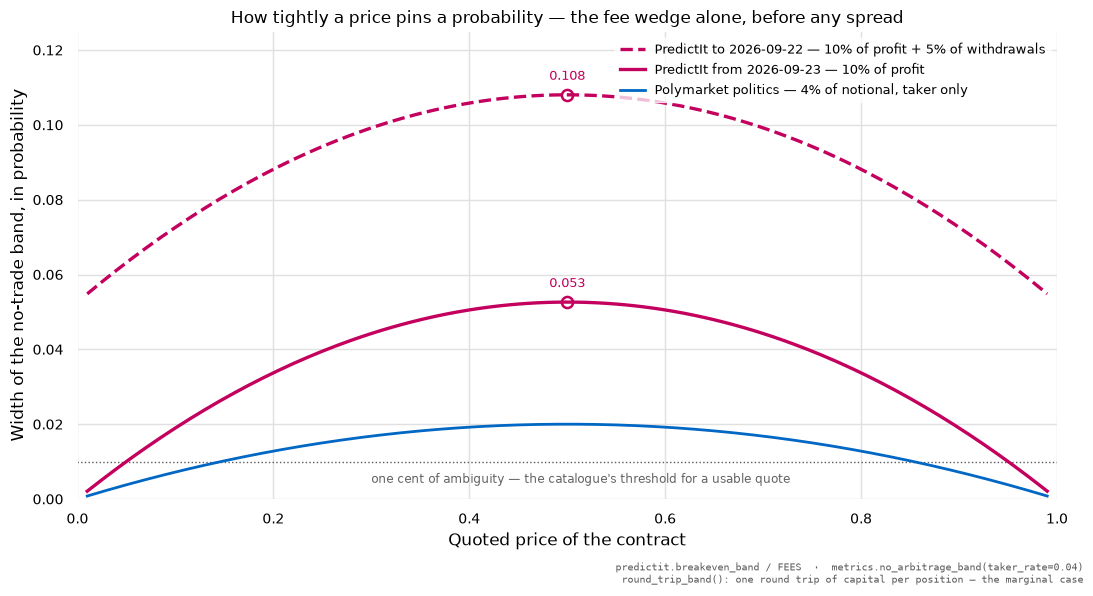

In [6]:
prices: NDArray[Any] = numpy.linspace(0.01, 0.99, 197)
legacy_width = numpy.array([numpy.diff(round_trip_band(p, 0.10, 0.05))[0] for p in prices])
simple_width = numpy.array([numpy.diff(round_trip_band(p, 0.10, 0.00))[0] for p in prices])
poly_width = numpy.array([metrics.no_arbitrage_band(float(p)) for p in prices])

figure, axis = pyplot.subplots(figsize=(11, 6))
axis.set_axisbelow(True)
axis.plot(prices, legacy_width, color=PREDICTIT, lw=2.4, ls="--",
          label="PredictIt to 2026-09-22 — 10% of profit + 5% of withdrawals")
axis.plot(prices, simple_width, color=PREDICTIT, lw=2.4,
          label="PredictIt from 2026-09-23 — 10% of profit")
axis.plot(prices, poly_width, color=POLYMARKET, lw=2.0,
          label="Polymarket politics — 4% of notional, taker only")
axis.axhline(0.01, color="0.35", lw=1, ls=":", zorder=1)
axis.text(0.30, 0.0043, "one cent of ambiguity — the catalogue's threshold for a usable quote",
          fontsize=8.5, alpha=0.95, color="0.35")

# Direct labels on the two widest points rather than a number on every series.
for width, colour, dy in ((legacy_width, PREDICTIT, 0.004), (simple_width, PREDICTIT, 0.004)):
    peak_index = int(numpy.argmax(width))
    axis.plot([prices[peak_index]], [width[peak_index]], marker="o", markersize=8,
              mfc="none", mew=1.8, color=colour, zorder=4)
    axis.annotate(f"{width[peak_index]:.3f}", (prices[peak_index], width[peak_index] + dy),
                  ha="center", fontsize=9, color=colour)

axis.set_xlim(0, 1)
axis.set_ylim(0, 0.125)
axis.set_xlabel("Quoted price of the contract")
axis.set_ylabel("Width of the no-trade band, in probability")
axis.set_title("How tightly a price pins a probability — the fee wedge alone, "
               "before any spread", fontsize=12)
axis.legend(loc="upper right", fontsize=9)
figure.tight_layout()
stamp_source("predictit.breakeven_band / FEES  ·  metrics.no_arbitrage_band(taker_rate=0.04)",
             "round_trip_band(): one round trip of capital per position — the marginal case",
             figure=figure)

### And then the spread, on top of the fee

The fee band is what the price cannot tell you even with a perfect market. The
spread is what the market adds. PredictIt serves four touch quotes and no size
behind them, so `bestBuyYesCost − bestSellYesCost` is a **true touch spread** —
it is the one liquidity measure this venue supports, and `metrics.VENUE_COVERAGE`
marks it `yes` while marking depth `no`.

The two wedges compose rather than compete: a trader must clear the spread *and*
the fee, so the belief needed to lift the offer is the fee-adjusted probability
of the **ask**, and the belief needed to hit the bid is the fee-adjusted
probability of the **bid**. The distance between those is the honest answer to
"what probability is this market quoting", and it is the number the rest of this
notebook means by a wedge.

They are not, though, the same *kind* of wedge, and the numbers below make the
difference visible. The spread is larger on most contracts and it is
contingent — it is a cent on the liquid ones and would narrow further with more
participants. The fee band is smaller and **irreducible**: it is charged on the
trade rather than quoted in the book, so no amount of depth touches it. It is
the floor under everything, and the floor is two and a half points.

In [7]:
def wedge(contract: dict[str, Any], regime: predictit.FeeRegime) -> dict[str, Any] | None:
    """Fee-and-spread band for one contract, or None if it is not two-sided.

    `fee_adjusted_probability` turns a touch price into the belief of whoever
    would take it, which is the correct reading of a touch under a profit fee.
    A midpoint is not that number and is not substituted for it.
    """
    ask, bid = contract.get("bestBuyYesCost"), contract.get("bestSellYesCost")
    if ask is None or bid is None or ask < bid:
        return None
    upper = predictit.fee_adjusted_probability(ask, "yes", regime)
    lower = predictit.fee_adjusted_probability(bid, "no", regime)
    return {"bid": bid, "ask": ask, "spread": ask - bid,
            "lower": lower, "upper": upper, "total": upper - lower,
            "fee_only": predictit.fee_band_width((ask + bid) / 2, regime)}


bands = [w for c in CONTRACTS if (w := wedge(c, REGIME)) is not None]
one_sided = len(CONTRACTS) - len(bands)
spreads = sorted(w["spread"] for w in bands)
totals = sorted(w["total"] for w in bands)

print(f"two-sided contracts: {len(bands)} of {len(CONTRACTS)}; "
      f"{one_sided} carry a null on one of the two Yes quotes")
print(f"\n{'measure':34} {'p10':>7} {'median':>7} {'p90':>7} {'max':>7}")


def quantiles(values: Sequence[float]) -> tuple[float, float, float, float]:
    ordered = sorted(values)
    pick = lambda q: ordered[min(len(ordered) - 1, int(q * len(ordered)))]
    return pick(0.10), statistics.median(ordered), pick(0.90), ordered[-1]


for label, values in (("touch spread (ask - bid)", spreads),
                      ("fee band at the midpoint", [w["fee_only"] for w in bands]),
                      ("fee + spread, total wedge", totals)):
    p10, med, p90, top = quantiles(values)
    print(f"{label:34} {p10:7.4f} {med:7.4f} {p90:7.4f} {top:7.4f}")

wider = sum(1 for w in bands if w["fee_only"] > w["spread"])
print(f"\ncontracts where the fee band is the WIDER of the two: {wider} of {len(bands)} "
      f"({100 * wider / len(bands):.0f}%)")
print("So the spread is usually the bigger number, and the two are not the same kind of")
print("number. The spread is contingent -- more participants would narrow it, and it is")
print("1c on the liquid contracts. The fee band is irreducible: no amount of depth moves")
print("it, because it is charged on the trade rather than quoted in the book. It is the")
print("floor under the wedge, and the floor is 2.5 points at the middle of the range.")

# The spread's own distribution is bimodal, and the tail is not liquidity: a
# 0.98-wide "spread" is a 0.01 bid against a 0.99 ask, which is the PredictIt
# analogue of Polymarket's zero-bid books -- a quote in form only.
real = [w for w in bands if w["spread"] <= 0.05]
fee_dominant = sum(1 for w in real if w["fee_only"] > w["spread"])
print(f"\namong the {len(real)} contracts with a spread of 5c or less -- a real market:")
print(f"  median spread {statistics.median([w['spread'] for w in real]):.4f}, "
      f"median fee band {statistics.median([w['fee_only'] for w in real]):.4f}, "
      f"fee wider on {fee_dominant} of {len(real)}")
print(f"  and {len(bands) - len(real)} contracts sit outside that, with spreads up to "
      f"{max(w['spread'] for w in bands):.2f}")
print(f"  every one of the {wider} fee-dominant contracts is inside that subset "
      f"({fee_dominant} of {wider}), which is the point: the fee is the binding wedge "
      "exactly where there is a market to bind.")

for threshold in (0.02, 0.05, 0.10, 0.20):
    n = sum(1 for t in totals if t > threshold)
    print(f"contracts whose price pins the probability no better than "
          f"+-{threshold / 2:.3f}: {n:>3} of {len(bands)}")

print(f"\n{'market':52} {'contract':22} {'bid':>5} {'ask':>5} {'wedge':>6}")
lookup = {c["id"]: m for m in MARKETS for c in m["contracts"]}
worst = sorted(((w, c) for c in CONTRACTS if (w := wedge(c, REGIME))), key=lambda p: -p[0]["total"])
for w, c in worst[:6]:
    print(f"{lookup[c['id']]['name'][:52]:52} {(c['name'] or '')[:22]:22} "
          f"{w['bid']:5.2f} {w['ask']:5.2f} {w['total']:6.3f}")
print("A 1c bid against a 99c ask is not a spread, it is the absence of a market wearing "
      "the shape of one -- and PredictIt serves no size, so nothing in the payload says so.")

two-sided contracts: 517 of 613; 96 carry a null on one of the two Yes quotes

measure                                p10  median     p90     max
touch spread (ask - bid)            0.0100  0.0300  0.5800  0.9800
fee band at the midpoint            0.0051  0.0246  0.0522  0.0526
fee + spread, total wedge           0.0152  0.0598  0.6070  0.9820

contracts where the fee band is the WIDER of the two: 117 of 517 (23%)
So the spread is usually the bigger number, and the two are not the same kind of
number. The spread is contingent -- more participants would narrow it, and it is
1c on the liquid contracts. The fee band is irreducible: no amount of depth moves
it, because it is charged on the trade rather than quoted in the book. It is the
floor under the wedge, and the floor is 2.5 points at the middle of the range.

among the 314 contracts with a spread of 5c or less -- a real market:
  median spread 0.0100, median fee band 0.0114, fee wider on 117 of 314
  and 203 contracts sit outside th

## 3. The position cap, which is what stands in for depth

PredictIt publishes **no size at all** — no depth at the touch, no levels
behind it, no open interest. `metrics.NOT_COMPUTABLE` carries an entry called
`predictit_depth` saying exactly that, and pointing at what replaces it: the
binding constraint on this venue is regulatory rather than microstructural, and
it is a *ceiling* rather than a measurement.

Two details in CFTC Letter No. 25-20 are easy to get wrong and both change the
arithmetic.

**The cap is per participant per *contract*, not per market.** Widely repeated
third-party reviews say per market, which understates permitted exposure on a
multi-rung ladder by the number of rungs: on an eleven-rung seat-count market
the same person may hold eleven times the cap against one question.

**The cap is indexed, not fixed.** It tracks the FECA individual contribution
limit — $3,500 at issue, re-indexed by the FEC every two years — so any code
that hard-codes the number drifts silently.

What a cap does to a price is make correcting a mispricing worth only so much.
The cell below computes that ceiling: the most a trader can earn by being right
about a five-point mispricing, at each price, after the profit fee.

In [8]:
print(f"source: {predictit.LIMITS['source']}")
for key in ("investment_cap_scope", "investment_cap_basis", "investment_cap_usd_at_issue",
            "investment_cap_is_indexed", "traders_per_contract_limit",
            "traders_per_contract_limit_before", "trader_cap_removed_on",
            "operator", "contract_selection"):
    print(f"  {key:34} {predictit.LIMITS[key]}")

CAP = float(predictit.LIMITS["investment_cap_usd_at_issue"])
EDGE = 0.05

print(f"\nThe most one participant can earn from a {EDGE:.2f} edge, at the ${CAP:,.0f} "
      f"per-contract cap, after the {REGIME.profit_fee:.0%} profit fee:")
print(f"{'price':>6}  {'shares at the cap':>17}  {'edge per share':>14}  {'max expected $':>14}")
for price in (0.02, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90):
    shares = CAP / price
    # Value of one share to a trader who believes price+EDGE: the fee-reduced
    # payoff times the belief, less what the share costs.
    per_share = (price + EDGE) * predictit.net_payoff_per_share(price, REGIME) - price
    print(f"{price:6.2f}  {shares:17,.0f}  {per_share:14.4f}  {shares * per_share:14,.0f}")

print("\nThe cheap rows of that column are not comparable to the rest: a five-point edge at")
print("two cents is a 3.5x mispricing rather than a marginal one, and no market leaves that")
print("standing. The rows to read are the middle ones -- correcting a five-point error on a")
print("coin-flip contract is worth about $157 to the one participant who spots it, at the cap.")
print("That is the ceiling on what research into this venue's prices can pay, per contract.")

print(f"\nAnd across a ladder, because the cap is per contract:")
for rungs in (1, 2, 11, 18):
    print(f"  {rungs:>2} rungs -> ${CAP * rungs:>9,.0f} of permitted exposure to one question")
print(f"largest market in the snapshot: {max(len(m['contracts']) for m in MARKETS)} contracts, "
      f"so ${CAP * max(len(m['contracts']) for m in MARKETS):,.0f} for one participant")

source: CFTC Letter No. 25-20, 2025-07-14, amending CFTC Letter No. 14-130
  investment_cap_scope               per participant, per contract
  investment_cap_basis               FECA individual contribution limit per election per candidate
  investment_cap_usd_at_issue        3500
  investment_cap_is_indexed          True
  traders_per_contract_limit         None
  traders_per_contract_limit_before  5000
  trader_cap_removed_on              2025-07-14
  operator                           Prediction Market Research Consortium, Inc. (PMRC), a US not-for-profit
  contract_selection                 a board of academics from US universities, staggered two-year terms

The most one participant can earn from a 0.05 edge, at the $3,500 per-contract cap, after the 10% profit fee:
 price  shares at the cap  edge per share  max expected $
  0.02            175,000          0.0431           7,550
  0.05             70,000          0.0405           2,835
  0.10             35,000          0.0365   

### Volume is not interest, and here it is barely anything

On Polymarket the lesson about volume is that it is unusable: one event reported
$1.29bn against $10.1m of open interest, 128× turnover, with 87% of a sibling
event's volume sitting in outcomes priced under two cents. PredictIt's version
of the lesson is shorter. **There is no open interest field**, so turnover
cannot be computed at all; and volume exists only inside the seven-day chart
endpoint, in *shares* rather than dollars, for the first six contracts of a
market.

A share settles at no more than $1, so share volume is an upper bound on dollar
volume and not the same number. The comparison worth making is against the
structural cap from the section above: on the venue's flagship ladder, one
participant at the per-contract ceiling could account for several days of the
whole market's trading.

In [9]:
CHARTS: dict[str, list[dict[str, Any]]] = SNAP["charts"]
LADDER_ID = 7589
by_id: dict[int, dict[str, Any]] = {m["id"]: m for m in MARKETS}
ladder_market = by_id[LADDER_ID]
chart = predictit.chart_rows(CHARTS[str(LADDER_ID)])

print(f"{ladder_market['name']}\n")
days = sorted({r["date"] for r in chart})
print(f"chart window: {days[0]} .. {days[-1]}  ({len(days)} days, "
      f"{len({r['contract_id'] for r in chart})} of {len(ladder_market['contracts'])} contracts)")

print(f"\n{'date':11} {'shares traded':>13} {'<= dollars':>11}  (six charted rungs only)")
for day in days:
    shares = sum(r["share_volume"] or 0 for r in chart if r["date"] == day)
    print(f"{day:11} {shares:13,} {shares:11,}")
total = sum(r["share_volume"] or 0 for r in chart)
print(f"{'seven days':11} {total:13,} {total:11,}")
print(f"\nOne participant holding the ${CAP:,.0f} cap on every one of this market's "
      f"{len(ladder_market['contracts'])} rungs -- ${CAP * len(ladder_market['contracts']):,.0f} "
      f"in all -- would be {CAP * len(ladder_market['contracts']) / max(total, 1):.1f}x the "
      "market's entire seven-day share volume, and that is an underestimate: a share costs "
      "at most a dollar and these cost two to thirty-six cents.")
print("Two caveats and both cut the same way. The chart covers six of eleven rungs, so the "
      "true volume is higher; and the seven days are one week in September, not a season.")

coverage = predictit.chart_coverage(ladder_market, CHARTS[str(LADDER_ID)])
for key in ("n_contracts", "n_charted", "n_missing", "complete"):
    print(f"  {key:12} {coverage[key]}")

print("\nWhat the catalogue says is unavailable here, and why:")
for name in ("open_interest", "volume_to_open_interest_turnover", "time_since_last_trade",
             "depth_within_1c / depth_within_5c"):
    verdict, note = metrics.VENUE_COVERAGE[name]["predictit"]
    print(f"\n  {name}  [{verdict}]")
    print(textwrap.fill(note, 74, initial_indent="    ", subsequent_indent="    "))

How many House seats will Republicans win in the 2026 midterm election?

chart window: 2026-09-19 .. 2026-09-25  (7 days, 6 of 11 contracts)

date        shares traded  <= dollars  (six charted rungs only)
2026-09-19          1,050       1,050
2026-09-20            449         449
2026-09-21          1,092       1,092
2026-09-22          1,347       1,347
2026-09-23          3,525       3,525
2026-09-24          1,231       1,231
2026-09-25          2,783       2,783
seven days         11,477      11,477

One participant holding the $3,500 cap on every one of this market's 11 rungs -- $38,500 in all -- would be 3.4x the market's entire seven-day share volume, and that is an underestimate: a share costs at most a dollar and these cost two to thirty-six cents.
Two caveats and both cut the same way. The chart covers six of eleven rungs, so the true volume is higher; and the seven days are one week in September, not a season.
  n_contracts  11
  n_charted    6
  n_missing    5
  complete  

## 4. The ladder is a distribution

This is the idea worth the most in the whole project, and PredictIt happens to
carry a clean example of it.

A row of contracts indexed by a **threshold** is a cumulative distribution
function over the outcome. Adjacent rungs difference into the probability mass
in each interval, exactly as an option strike ladder differences into a density
over price. Polymarket's version of the object is a row of *"X happens by date
T"* markets, where the axis is the resolution date. PredictIt's is a row of
seat-count buckets, where the axis is **ordinal rather than temporal** — "192 or
fewer", "193 to 197", "198 to 202" and so on up.

The difference between the two axes matters in one place and is worth naming
before the arithmetic. On a date ladder the rungs are *cumulative* by
construction — "by June" is a subset of "by December" — and they are also
**discounted differently**, because each rung settles at a different time, so
`metrics.discount_adjust_ladder` has to run before any differencing or the
discount gradient manufactures negative mass. On a seat ladder the rungs are
*exclusive* buckets that must be cumulated by hand, and every rung settles on
the **same day**, so the discount is common to all of them: it scales the whole
curve and cancels out of every difference. That is why `apply_discount=False`
below, and why the discount shows up in the **sum** of the ladder rather than in
its shape.

Which means the sum is worth looking at first.

In [10]:
BUCKET_RE = (
    re.compile(r"^(?P<hi>\d+)\s+or\s+fewer", re.I),      # open below
    re.compile(r"^(?P<lo>\d+)\s+to\s+(?P<hi>\d+)", re.I),
    re.compile(r"^(?P<lo>\d+)\s+or\s+more", re.I),        # open above
    re.compile(r"^(?P<lo>\d+)\s*$"),
)


def seat_ladder(market: dict[str, Any], price_key: str = "lastTradePrice") -> list[dict[str, Any]]:
    """Order an exclusive bucket market along its ordinal axis and cumulate it.

    `displayOrder` is 0 on every contract of market 7589, so it cannot be used
    for ordering; the bucket's own seat numbers are the only reliable key.

    The two end buckets are open -- "192 or fewer" below, "238 or more" above --
    so they have no width of their own.  Each is given the **modal width of the
    closed buckets**, which for the House ladder is five seats and for the
    Senate ladder one.  That is a stated convention rather than a measurement,
    and it matters only for the per-seat columns: it leaves the cumulative curve,
    the bucket masses and the implied quantiles untouched.
    """
    parsed: list[dict[str, Any]] = []
    for contract in market["contracts"]:
        name = contract["name"] or ""
        for pattern in BUCKET_RE:
            if (match := pattern.match(name)) is None:
                continue
            groups = match.groupdict()
            lo = int(groups["lo"]) if groups.get("lo") else None
            hi = int(groups["hi"]) if groups.get("hi") else None
            parsed.append({"label": name, "lower": lo, "upper": hi,
                           "price": contract[price_key],
                           "bid": contract.get("bestSellYesCost"),
                           "ask": contract.get("bestBuyYesCost")})
            break
    parsed.sort(key=lambda r: r["lower"] if r["lower"] is not None else r["upper"])

    closed = [r["upper"] - r["lower"] + 1 for r in parsed
              if r["lower"] is not None and r["upper"] is not None]
    modal = Counter(closed).most_common(1)[0][0] if closed else 1
    for rung in parsed:
        if rung["lower"] is None:                       # "N or fewer"
            rung["lower"] = rung["upper"] - modal + 1
        if rung["upper"] is None:                       # "N or more"
            rung["upper"] = rung["lower"] + modal - 1
        rung["width"] = rung["upper"] - rung["lower"] + 1
        rung["open_ended"] = rung is parsed[0] or rung is parsed[-1]

    running = 0.0
    for rung in parsed:
        running += rung["price"]
        rung["cdf"] = running
    return parsed


for market_id in (7589, 8163):
    market = by_id[market_id]
    rungs = seat_ladder(market)
    ask_sum = sum(r["ask"] for r in rungs if r["ask"] is not None)
    bid_sum = sum(r["bid"] for r in rungs if r["bid"] is not None)
    last_sum = sum(r["price"] for r in rungs)
    print(f"\n{market['name']}")
    print(f"  {len(rungs)} exclusive buckets; exactly one settles at $1")
    print(f"  sum of asks {ask_sum:.4f}   sum of last trades {last_sum:.4f}   "
          f"sum of bids {bid_sum:.4f}")
    print(f"  cost to buy the whole field at the offer: ${ask_sum:.4f} for a $1 payout "
          f"-- a {ask_sum - 1:+.4f} overround")
    print(f"  proceeds from selling the whole field at the bid: ${bid_sum:.4f} "
          f"-- a {bid_sum - 1:+.4f} {'credit' if bid_sum > 1 else 'debit'}")
    # The discount argument: all rungs settle on the same day, so a capital
    # lock-up discount would pull the sum BELOW one. Both sums sit above it.
    print(f"  a lock-up discount would push this sum below 1.0; it is "
          f"{'above' if last_sum > 1 else 'below'}, so the fee-and-spread overround "
          "dominates anything the discount could contribute")


How many House seats will Republicans win in the 2026 midterm election?
  11 exclusive buckets; exactly one settles at $1
  sum of asks 1.1800   sum of last trades 1.0100   sum of bids 1.0100
  cost to buy the whole field at the offer: $1.1800 for a $1 payout -- a +0.1800 overround
  proceeds from selling the whole field at the bid: $1.0100 -- a +0.0100 credit
  a lock-up discount would push this sum below 1.0; it is above, so the fee-and-spread overround dominates anything the discount could contribute

How many Senate seats will the GOP control after the 2026 midterms?
  11 exclusive buckets; exactly one settles at $1
  sum of asks 1.1800   sum of last trades 1.1300   sum of bids 1.0500
  cost to buy the whole field at the offer: $1.1800 for a $1 payout -- a +0.1800 overround
  proceeds from selling the whole field at the bid: $1.0500 -- a +0.0500 credit
  a lock-up discount would push this sum below 1.0; it is above, so the fee-and-spread overround dominates anything the discount c

Both ladders show a sum of bids **above one**, which looks like free money: sell
every bucket at the bid, collect more than the dollar you will owe. It is the
cleanest possible demonstration of why the fee schedule is not a detail, because
the trade is riskless and the fee still kills it.

The trade on PredictIt is to buy the **No** side of every bucket. Exactly one
bucket settles Yes, so ten of the eleven No positions pay $1 and one pays
nothing. The gross edge is a cent or five. The fee is charged on each winning
position separately, with no offset for the loser, so ten winners pay ten
fees — and how much they pay depends on **which bucket wins**, which the trader
does not know when they put the trade on.

In [11]:
def short_the_field(market: dict[str, Any], regime: predictit.FeeRegime) -> dict[str, Any] | None:
    """Buy No on every bucket: the riskless trade, and what the profit fee does to it.

    Cost is the sum of the No asks.  Exactly one bucket settles Yes, so the
    payout is `n - 1` dollars.  The fee is `profit_fee` times the gross profit
    on each *winning* No position, summed -- never netted against the loser.
    """
    asks = [c.get("bestBuyNoCost") for c in market["contracts"]]
    if any(a is None for a in asks):
        return None
    n = len(asks)
    cost = float(sum(asks))
    payout = float(n - 1)
    gross = payout - cost
    # If bucket j settles Yes, the winners are every i != j.
    outcomes = []
    for j in range(n):
        fee = regime.profit_fee * sum(1.0 - a for i, a in enumerate(asks) if i != j)
        outcomes.append((market["contracts"][j]["name"], fee, gross - fee))
    return {"n": n, "cost": cost, "payout": payout, "gross": gross, "outcomes": outcomes}


for market_id in (7589, 8163):
    market = by_id[market_id]
    trade = short_the_field(market, REGIME)
    print(f"\n{market['name'][:76]}")
    if trade is None:
        print("  a bucket has no No offer; the trade cannot be priced")
        continue
    print(f"  buy No on all {trade['n']} buckets for ${trade['cost']:.4f}; "
          f"${trade['payout']:.2f} comes back; gross edge {trade['gross']:+.4f}")
    best = min(trade["outcomes"], key=lambda o: o[1])
    worst = max(trade["outcomes"], key=lambda o: o[1])
    print(f"  fee if '{best[0]}' wins:  {best[1]:.4f}  ->  net {best[2]:+.4f}")
    print(f"  fee if '{worst[0]}' wins: {worst[1]:.4f}  ->  net {worst[2]:+.4f}")
    print(f"  net across all {trade['n']} outcomes: "
          f"{min(o[2] for o in trade['outcomes']):+.4f} to "
          f"{max(o[2] for o in trade['outcomes']):+.4f}  "
          f"-- {'never' if all(o[2] < 0 for o in trade['outcomes']) else 'sometimes'} positive")
    print(f"  the fee is {worst[1] / trade['gross']:.1f}x the gross edge at worst, "
          f"and the trader cannot know which outcome they will get")


How many House seats will Republicans win in the 2026 midterm election?
  buy No on all 11 buckets for $9.9900; $10.00 comes back; gross edge +0.0100
  fee if '192 or fewer' wins:  0.0670  ->  net -0.0570
  fee if '228 to 232' wins: 0.0990  ->  net -0.0890
  net across all 11 outcomes: -0.0890 to -0.0570  -- never positive
  the fee is 9.9x the gross edge at worst, and the trader cannot know which outcome they will get

How many Senate seats will the GOP control after the 2026 midterms?
  buy No on all 11 buckets for $9.9500; $10.00 comes back; gross edge +0.0500
  fee if '47 or fewer' wins:  0.0720  ->  net -0.0220
  fee if '54' wins: 0.1030  ->  net -0.0530
  net across all 11 outcomes: -0.0530 to -0.0220  -- never positive
  the fee is 2.1x the gross edge at worst, and the trader cannot know which outcome they will get


### Judging the ladder on its own coherence

With the sum understood, the shape can be read. A ladder is testable in ways a
single market never is, and the tests need no outside information at all:

* the cumulative curve must be **non-decreasing** across the buckets;
* the **interval masses** must be non-negative and sum to at most one;
* the implied **hazard** — the chance of landing in a bucket given the count has
  not already been passed — must be a plausible shape, and a near-constant
  hazard across many rungs is the signature of one participant interpolating
  rather than many pricing independently;
* the **terminal mass** beyond the last rung says how much of the question the
  ladder prices at all.

`metrics.ladder_report` does all of it, and it takes rungs keyed by a `date`. A
seat ladder has no dates, so the seat axis is mapped **one synthetic day per
seat**, each rung sitting at its bucket's upper edge, and the report's per-day
quantities then read as per-seat. That is a coordinate change rather than a
fudge: the hazard rate `−ln(1 − h)/days` becomes a force of resolution per seat,
which is the right thing to compare across buckets of unequal width, and the
House ladder's two end buckets are open-ended so they take the modal width of
the closed ones by stated convention.

Two of the four structural tests turn out to be tautologies on a ladder built
this way, and the cell says which — a point that matters more than it looks,
because it is the difference between the two kinds of ladder.

In [12]:
ANCHOR = date(2026, 11, 3)          # election day, purely as the axis origin


def as_rungs(rungs: Sequence[dict[str, Any]]) -> list[metrics.Rung]:
    """Map the seat axis onto the date axis, one synthetic day per seat.

    `metrics.Rung` keys on a date because the reference ladders are date
    ladders.  Placing each rung at its bucket's **upper** edge is what makes the
    interval between consecutive rungs equal to the bucket's width in seats, so
    every per-day quantity the report returns reads as per-seat and the hazard
    shape survives the coordinate change rather than being flattened by equal
    spacing.

    `bid` and `ask` are deliberately dropped: the rungs are cumulative, so a
    cumulative touch would be the sum of the bids over every bucket up to that
    rung -- an eleven-leg execution on a venue that publishes no size at all.
    Passing the per-bucket touch instead would make the arbitrage test compare
    two quantities that are not comparable.
    """
    return [metrics.Rung(label=r["label"],
                         horizon=date.fromordinal(ANCHOR.toordinal() + r["upper"]),
                         price=r["cdf"])
            for r in rungs]


def axis_origin(rungs: Sequence[dict[str, Any]]) -> date:
    """The point the first interval is measured from: the bottom bucket's lower edge."""
    return date.fromordinal(ANCHOR.toordinal() + rungs[0]["lower"] - 1)


ladder = seat_ladder(by_id[LADDER_ID])
# apply_discount=False: every bucket settles on election day, so the discount is
# common to all of them and cancels out of the differences. Applying a horizon
# discount here would gross up the far buckets by their *seat* distance from the
# origin, which is meaningless.
report = metrics.ladder_report(as_rungs(ladder), asof=axis_origin(ladder),
                               apply_discount=False)


def fmt(value: float | int | None, spec: str = "10.4f") -> str:
    """A number in `spec`, right-aligned, or a dash of the same width if there is none."""
    width = int(re.match(r"\d+", spec).group())
    return f"{value:{spec}}" if value is not None else f"{'--':>{width}}"


print(f"{by_id[LADDER_ID]['name']}\n")
print(f"{'bucket':16} {'mass':>6} {'CDF':>6} {'seats':>6} "
      f"{'mass/seat':>10} {'hazard':>7} {'force/seat':>10}")
for row, hz in zip(report["interval_mass"], report["hazard"]):
    print(f"{row['label'][:16]:16} "
          f"{row['mass']:6.3f} {row['cumulative']:6.3f} "
          f"{fmt(row['interval_days'], '6d')} "
          f"{fmt(row['mass_per_day'])} "
          f"{fmt(hz['hazard'], '7.3f')} "
          f"{fmt(hz['hazard_rate_per_day'])}")

seats = lambda when: when.toordinal() - ANCHOR.toordinal()
print(f"\nmonotone across the buckets           {report['monotonicity']['monotone']}")
print(f"negative masses                       {report['n_negative_mass']}")
print(f"implausible hazards                   {report['n_implausible_hazard']}")
print(f"terminal mass beyond the last bucket  {report['terminal']['terminal_mass']:+.4f}")
print(f"implied quartiles, in seats:  q25 {seats(report['implied_q25'])}, "
      f"median {seats(report['implied_median'])}, q75 {seats(report['implied_q75'])}")

plausible = [h["hazard"] for h in report["hazard"] if not h["implausible"]]
print(f"\nhazard across the {len(plausible)} plausible buckets: "
      f"{min(plausible):.3f} to {max(plausible):.3f}")

print("\nThe last two lines are the coherence machinery earning its keep, not a bug.")
print(f"  The ladder's prices sum to {ladder[-1]['cdf']:.3f}, a cent over a dollar, so the")
print("  cumulative curve walks past 1.0 and the leftover mass comes out NEGATIVE. The")
print("  hazard on the final rung then divides a mass by a survival probability that is")
print("  already negative, giving 2.000 -- which is not a conditional probability, and")
print("  `implausible` flags it rather than clipping it. A one-cent overround at the top of")
print("  an eleven-rung ladder is enough to break the last rung's arithmetic entirely, and")
print("  the flag is what tells you the input rather than the market is at fault.")

print("\nTwo of the first four lines are tautologies here, and saying which is the point.")
print("  On an EXCLUSIVE bucket ladder cumulated by hand, the prices are non-negative by")
print("  construction, so monotonicity and non-negative mass cannot fail. They are real")
print("  tests only on a DATE ladder, where each rung is independently quoted as its own")
print("  cumulative probability and 'by June' can be quoted above 'by December'.")
print("  What tests this ladder is the sum (above), the hazard SHAPE, and the terminal mass.")
print("\n  The arbitrage test is not run at all: a cumulative touch is the sum of eleven")
print("  bucket touches, an eleven-leg execution on a venue publishing no size -- see")
print("  metrics.NOT_COMPUTABLE['predictit_depth']. An empty arbitrage list here would mean")
print("  'not measured', not 'nothing there', so the rungs carry no bid or ask.")
print("\n  The hazard varying across buckets is what independent pricing looks like; a hazard")
print("  near-constant to two figures across many rungs is the signature of one participant")
print("  interpolating, which is what the reference ceasefire ladder shows on Polymarket.")

How many House seats will Republicans win in the 2026 midterm election?

bucket             mass    CDF  seats  mass/seat  hazard force/seat
192 or fewer      0.340  0.340      5     0.0680   0.340     0.0831
193 to 197        0.130  0.470      5     0.0260   0.197     0.0439
198 to 202        0.150  0.620      5     0.0300   0.283     0.0665
203 to 207        0.160  0.780      5     0.0320   0.421     0.1093
208 to 212        0.070  0.850      5     0.0140   0.318     0.0766
213 to 217        0.040  0.890      5     0.0080   0.267     0.0620
218 to 222        0.030  0.920      5     0.0060   0.273     0.0637
223 to 227        0.030  0.950      5     0.0060   0.375     0.0940
228 to 232        0.020  0.970      5     0.0040   0.400     0.1022
233 to 237        0.020  0.990      5     0.0040   0.667     0.2197
238 or more       0.020  1.010      5     0.0040   2.000         --

monotone across the buckets           True
negative masses                       0
implausible hazards        

### The truncation that makes the historical ladder unreadable

There is a trap in the one history endpoint PredictIt does serve, and it lands
precisely on the object worth studying. `GetMarketChartData` returns **only the
first six contracts of a market**, silently — no error, no marker, no count.
On the eleven-rung House ladder the six it returns are the *bottom* six, so the
five buckets it drops are the whole upper tail of the distribution.

A CDF read from the chart endpoint is therefore a **truncated CDF presented as a
complete one**, and every derived quantity inherits the truncation: the terminal
mass reads as leftover probability rather than as missing rungs, and the hazard
on the last charted bucket is computed against the wrong survival. The figure
puts the two curves side by side.

In [13]:
charted_ids = {r["contract_id"] for r in chart}
charted_names = {c["name"] for c in ladder_market["contracts"] if c["id"] in charted_ids}
visible = [r for r in ladder if r["label"] in charted_names]
hidden = [r for r in ladder if r["label"] not in charted_names]

print(f"charted: {[r['label'] for r in visible]}")
print(f"dropped: {[r['label'] for r in hidden]}\n")

truncated = metrics.ladder_report(as_rungs(visible), asof=axis_origin(visible),
                                  apply_discount=False)
print(f"{'':28} {'from the chart':>15} {'from the snapshot':>18}")
print(f"{'rungs':28} {truncated['n_rungs']:>15} {report['n_rungs']:>18}")
print(f"{'last cumulative value':28} {truncated['terminal']['last_cumulative']:>15.3f} "
      f"{report['terminal']['last_cumulative']:>18.3f}")
print(f"{'terminal mass':28} {truncated['terminal']['terminal_mass']:>15.3f} "
      f"{report['terminal']['terminal_mass']:>18.3f}")
print(f"{'hazard on the last rung':28} {truncated['hazard'][-1]['hazard']:>15.3f} "
      f"{report['hazard'][-1]['hazard']:>18.3f}")
print(f"{'implied median, in seats':28} {seats(truncated['implied_median']):>15} "
      f"{seats(report['implied_median']):>18}")
print(f"\nmass hidden from the chart endpoint: {sum(r['price'] for r in hidden):.3f}")
print("The implied median survives because the missing mass is all in the far tail; "
      "the terminal mass and the last rung's hazard do not.")

print(f"\nchart truncation across the ten markets whose charts were recorded:")
print(f"{'market':56} {'listed':>6} {'charted':>7} {'missing':>7}")
for key in CHARTS:
    market = by_id[int(key)]
    cov = predictit.chart_coverage(market, CHARTS[key])
    print(f"{market['name'][:56]:56} {cov['n_contracts']:>6} {cov['n_charted']:>7} "
          f"{cov['n_missing']:>7}")
complete = sum(1 for k in CHARTS if predictit.chart_coverage(by_id[int(k)], CHARTS[k])["complete"])
print(f"complete: {complete} of {len(CHARTS)} -- and the two that are complete are the two "
      "with fewer than seven contracts")

charted: ['192 or fewer', '193 to 197', '198 to 202', '203 to 207', '208 to 212', '213 to 217']
dropped: ['218 to 222', '223 to 227', '228 to 232', '233 to 237', '238 or more']

                              from the chart  from the snapshot
rungs                                      6                 11
last cumulative value                  0.890              1.010
terminal mass                          0.110             -0.010
hazard on the last rung                0.267              2.000
implied median, in seats                 198                198

mass hidden from the chart endpoint: 0.120
The implied median survives because the missing mass is all in the far tail; the terminal mass and the last rung's hazard do not.

chart truncation across the ten markets whose charts were recorded:
market                                                   listed charted missing
Who will be the next Cabinet member to leave office?         18       6      12
Who will win the 2028 Democratic pr

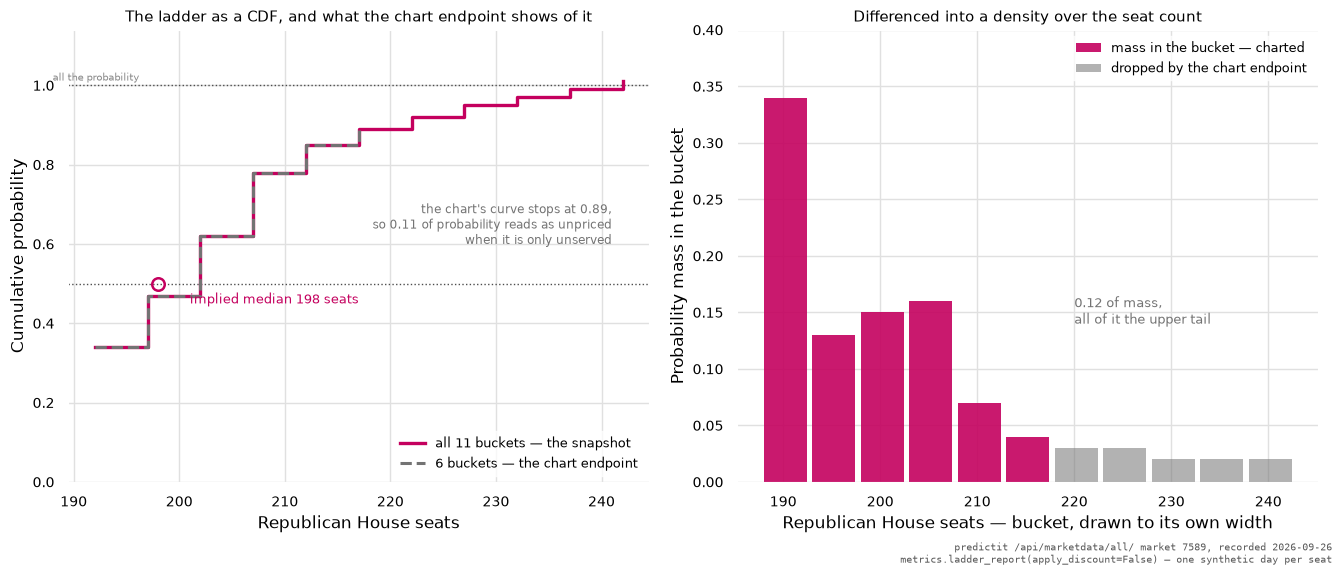

In [14]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13.5, 5.8))

left.set_axisbelow(True)
# A CDF steps up at each bucket's upper edge, so the step goes after the point.
left.step([r["upper"] for r in ladder], [r["cdf"] for r in ladder], where="post",
          color=PREDICTIT, lw=2.4, label=f"all {len(ladder)} buckets — the snapshot")
left.step([r["upper"] for r in visible], [r["cdf"] for r in visible], where="post",
          color=GREY, lw=2.2, ls="--",
          label=f"{len(visible)} buckets — the chart endpoint")
left.axhline(1.0, color="0.3", lw=1, ls=":", zorder=1)
left.axhline(0.5, color="0.3", lw=1, ls=":", zorder=1)
left.text(ladder[0]["lower"], 1.012, "all the probability", fontsize=7.5, alpha=0.85,
          color=GREY)
median_seats = seats(report["implied_median"])
left.plot([median_seats], [0.5], marker="o", markersize=9, mfc="none", mew=1.8,
          color=PREDICTIT, zorder=4)
left.annotate(f"implied median {median_seats} seats", (median_seats + 3, 0.45),
              fontsize=9, color=PREDICTIT)
left.annotate(f"the chart's curve stops at "
              f"{truncated['terminal']['last_cumulative']:.2f},\nso "
              f"{truncated['terminal']['terminal_mass']:.2f} of probability reads as "
              "unpriced\nwhen it is only unserved",
              (ladder[-1]["upper"] - 1, 0.60), ha="right", fontsize=8.5, color=GREY)
left.set_ylim(0, 1.14)
left.set_xlabel("Republican House seats")
left.set_ylabel("Cumulative probability")
left.set_title("The ladder as a CDF, and what the chart endpoint shows of it", fontsize=11)
left.legend(loc="lower right", fontsize=9)

right.set_axisbelow(True)
for rung in ladder:
    shown = rung["label"] in charted_names
    right.bar([rung["lower"]], [rung["price"]], width=rung["width"] * 0.88, align="edge",
              color=PREDICTIT if shown else GREY, alpha=0.9 if shown else 0.55,
              label=("mass in the bucket — charted" if rung is ladder[0] else
                     "dropped by the chart endpoint" if rung is hidden[0] else None))
right.annotate(f"{sum(r['price'] for r in hidden):.2f} of mass,\nall of it the upper tail",
               (hidden[0]["lower"] + 2, 0.14), fontsize=9, color=GREY)
right.set_ylim(0, 0.40)
right.set_xlabel("Republican House seats — bucket, drawn to its own width")
right.set_ylabel("Probability mass in the bucket")
right.set_title("Differenced into a density over the seat count", fontsize=11)
right.legend(loc="upper right", fontsize=9)

figure.tight_layout()
stamp_source(f"predictit /api/marketdata/all/ market {LADDER_ID}, recorded "
             f"{SNAP['captured_at'][:10]}",
             "metrics.ladder_report(apply_discount=False) — one synthetic day per seat",
             figure=figure)

## 5. No history without recording it yourself

Put the two facts from section 1 together — one endpoint, present tense only —
and the consequence is that **PredictIt's history is something you create**.
`predictit.record_snapshot` writes one dated file per run and never overwrites,
so a series accumulates from the day the recorder starts, and nothing before
that first run is ever recoverable from the API.

The seven-day chart window makes the recorder forgiving rather than fragile: a
week's outage backfills, which is why the sensible cadence is the snapshot daily
and the chart sweep weekly. It also gives a way to check the two endpoints
against each other, which the cell below does — the snapshot's `lastClosePrice`
should be the chart's previous-day close, and if it is, the two can be spliced
without a seam.

This corpus holds two snapshots taken ten minutes apart, which is a thinner
history than the venue deserves and exactly the right amount to demonstrate what
the recorder measures.

In [15]:
first, second = (predictit.load_snapshot(p) for p in SNAPSHOTS[:2])
flatten = lambda snap: {(m["id"], c["id"]): c
                        for m in snap["markets"] for c in m["contracts"]}
a, b = flatten(first), flatten(second)
shared = sorted(set(a) & set(b))

print(f"{SNAPSHOTS[0].name}  {first['captured_at']}")
print(f"{SNAPSHOTS[1].name}  {second['captured_at']}")
gap = (datetime.fromisoformat(second["captured_at"])
       - datetime.fromisoformat(first["captured_at"])).total_seconds()
print(f"{gap / 60:.0f} minutes apart, {len(shared)} contracts in both\n")

for field in ("lastTradePrice", "bestBuyYesCost", "bestSellYesCost", "lastClosePrice"):
    moved = sum(1 for k in shared if a[k].get(field) != b[k].get(field))
    print(f"{field:17} changed on {moved:>3} of {len(shared)} contracts")

captured = datetime.fromisoformat(second["captured_at"])
print(f"\nMeasured on a {captured:%A}. That is the whole caveat: a weekend reading "
      "of a political venue five weeks before a midterm says nothing about a Tuesday "
      "in late October, and the recorder is what would tell us.")
print("What it does establish is that a daily cadence loses nothing here -- and it is "
      "consistent with the catalogue's verdict that time_since_last_trade is "
      "uncomputable on this venue, since lastTradePrice carries no timestamp at all.")

# Reconcile the two endpoints on the six charted rungs.
print(f"\nDoes the snapshot's lastClosePrice equal the chart's previous-day close?")
print(f"{'rung':16} {'chart close ' + days[-1]:>22} {'snapshot lastClose':>19} "
      f"{'snapshot lastTrade':>19}")
agree = 0
for rung in visible:
    contract = next(c for c in ladder_market["contracts"] if c["name"] == rung["label"])
    row = next(r for r in chart if r["contract_name"] == rung["label"] and r["date"] == days[-1])
    match = abs((row["close"] or 0) - (contract["lastClosePrice"] or -1)) < 1e-9
    agree += match
    print(f"{rung['label'][:16]:16} {row['close']:>22.2f} {contract['lastClosePrice']:>19.2f} "
          f"{contract['lastTradePrice']:>19.2f}  {'=' if match else 'differs'}")
print(f"\n{agree} of {len(visible)} agree exactly, so the two endpoints reconcile and a "
      "recorded series can be backfilled seven days from the chart without a seam.")
biggest = max(visible, key=lambda r: abs(
    next(c for c in ladder_market["contracts"] if c["name"] == r["label"])["lastClosePrice"]
    - next(c for c in ladder_market["contracts"] if c["name"] == r["label"])["lastTradePrice"]))
contract = next(c for c in ladder_market["contracts"] if c["name"] == biggest["label"])
print(f"The last trade and the last close differ most on '{biggest['label']}': "
      f"{contract['lastTradePrice']:.2f} against {contract['lastClosePrice']:.2f}. "
      f"Its touch is {biggest['bid']:.2f}/{biggest['ask']:.2f}, so the gap is the width of "
      "its own spread -- and because lastTradePrice carries no timestamp, that gap cannot "
      "be dated. It is not a seam between the endpoints; it is an undatable print.")

predictit-2026-09-26-1944.json  2026-09-26T19:44:54.770904+00:00
predictit-2026-09-26-1954.json  2026-09-26T19:54:58.420428+00:00
10 minutes apart, 613 contracts in both

lastTradePrice    changed on   0 of 613 contracts
bestBuyYesCost    changed on   0 of 613 contracts
bestSellYesCost   changed on   0 of 613 contracts
lastClosePrice    changed on   0 of 613 contracts

Measured on a Saturday. That is the whole caveat: a weekend reading of a political venue five weeks before a midterm says nothing about a Tuesday in late October, and the recorder is what would tell us.
What it does establish is that a daily cadence loses nothing here -- and it is consistent with the catalogue's verdict that time_since_last_trade is uncomputable on this venue, since lastTradePrice carries no timestamp at all.

Does the snapshot's lastClosePrice equal the chart's previous-day close?
rung             chart close 2026-09-25  snapshot lastClose  snapshot lastTrade
192 or fewer                       0.38     

## 6. What the metric catalogue can and cannot do here

`metrics.VENUE_COVERAGE` states, family by family, which venues support which
measure. Read down the PredictIt column and the shape of the venue appears:
everything that needs a book, a tape or a text is gone, and what remains is the
touch, the tick, the cross-sectional sum, and the fee.

The catalogue is written so that its **silences are deliberate** — a metric that
cannot be computed is named with the reason rather than quietly omitted — and
two of its `NOT_COMPUTABLE` entries exist specifically for this venue. The
second of them is the one that matters for section 8.

In [16]:
print(f"{'metric family':46} {'PredictIt':>10} {'IEM':>8}")
tally: Counter[str] = Counter()
for name, row in metrics.VENUE_COVERAGE.items():
    pi, ie = row["predictit"][0], row["iem"][0]
    tally[pi] += 1
    print(f"{name[:46]:46} {pi:>10} {ie:>8}")
print(f"\nPredictIt across {len(metrics.VENUE_COVERAGE)} families: "
      + ", ".join(f"{n} {k}" for k, n in sorted(tally.items())))

print("\nThe catalogue's named silences that belong to this venue:\n")
for key in ("predictit_depth", "predictit_pre_2025_price_quality"):
    print(f"  {key}")
    print(textwrap.fill(metrics.NOT_COMPUTABLE[key], 74,
                        initial_indent="    ", subsequent_indent="    "))
    print()

print("And the ones that are unavailable on every venue in the study, PredictIt included:")
for key in ("quote_age", "order_flow_toxicity", "market_maker_identity"):
    print(f"  {key}: " + textwrap.shorten(metrics.NOT_COMPUTABLE[key], 150))

metric family                                   PredictIt      IEM
depth_within_1c / depth_within_5c                      no       no
absolute_spread / relative_spread                     yes  partial
midpoint_vs_last_trade_divergence                     yes  partial
open_interest                                          no       no
volume_to_open_interest_turnover                       no       no
holder_count / holder_concentration                    no       no
time_since_last_trade                                  no  partial
quote_age                                              no       no
price_path_staleness / distinct_trading_days      partial      yes
time_to_resolution / market_age                   partial      yes
tick_size                                             yes      yes
negative_risk_membership                          partial      yes
outcome_price_sum                                     yes      yes
resolution_text_length / named_source                  no  par

## 7. Resolution — who decides, on what text

For Polymarket this question has a long answer: UMA's optimistic oracle, a bond,
a two-hour challenge window, a token-holder vote, three documented contested
resolutions in the hundreds of millions, and a `was_disputed` flag served in the
resolution record so the dispute is a queryable fact.

For PredictIt the answer is short, and the shortness is the finding. **No public
endpoint serves any resolution text.** The rules exist — every market page has a
Rules tab — but it is rendered client-side and nothing a script can reach
carries it. `predictit.RESOLUTION_TEXT_AVAILABLE` is `False` for that reason,
and every resolution-quality metric in the catalogue is therefore unavailable
here: not "returns None", but *not computable*.

What is knowable is the institutional answer, and it is unusual. PredictIt was
created in 2014 by Victoria University of Wellington as an academic
data-gathering instrument under CFTC no-action relief; it is now run by the
Prediction Market Research Consortium, a US not-for-profit, and **its contract
list is chosen by a board of academics on staggered two-year terms**. So the
question "who decides what a market means" has a real answer on this venue — a
university board — and the question "on what text" has none that can be
retrieved programmatically.

There is also no dispute record of any kind. The catalogue marks
`dispute_history` as `no` for PredictIt, which is not the same as saying
disputes do not happen.

In [17]:
print(f"predictit.RESOLUTION_TEXT_AVAILABLE = {predictit.RESOLUTION_TEXT_AVAILABLE}\n")

verdict, note = metrics.VENUE_COVERAGE["resolution_text_length / named_source"]["predictit"]
print(f"resolution_text_length / named_source  [{verdict}]")
print(textwrap.fill(note, 74, initial_indent="  ", subsequent_indent="  "))
verdict, note = metrics.VENUE_COVERAGE["dispute_history"]["predictit"]
print(f"\ndispute_history  [{verdict}]  {note}")

# What the resolution-quality metrics do with nothing to read. Printed rather
# than described, because the point is that the functions are honest about it.
print("\nwhat the resolution metrics return when there is no text to read:")
print(f"  resolution_text_length(None)          {metrics.resolution_text_length(None)}")
print(f"  names_machine_checkable_source(None)  {metrics.names_machine_checkable_source(None)}")
print(f"  resolution_quality(None)              {metrics.resolution_quality(None)}")
print(f"  dispute_flags(None)                   {metrics.dispute_flags(None)}")

print(f"\ninstitutions:")
print(f"  operator now     {predictit.LIMITS['operator']}")
print(f"  operator before  {predictit.LIMITS['operator_before']}")
print(f"  who picks the contracts  {predictit.LIMITS['contract_selection']}")

print("\nthe two dates that break this venue's price history:")
for when, what in predictit.STRUCTURAL_BREAKS:
    print(f"  {when}  {what}")

predictit.RESOLUTION_TEXT_AVAILABLE = False

resolution_text_length / named_source  [no]
  No endpoint serves rules text. It exists only as client-rendered HTML on
  the market page. Every resolution-quality metric is unavailable for this
  venue from the API.

dispute_history  [no]  Not served.

what the resolution metrics return when there is no text to read:
  resolution_text_length(None)          0
  names_machine_checkable_source(None)  False
  resolution_quality(None)              {'length': 0, 'names_source': False, 'consensus_standard': False, 'has_duration_test': False, 'durations': [], 'served': False}
  dispute_flags(None)                   {'served': False}

institutions:
  operator now     Prediction Market Research Consortium, Inc. (PMRC), a US not-for-profit
  operator before  Victoria University of Wellington
  who picks the contracts  a board of academics from US universities, staggered two-year terms

the two dates that break this venue's price history:
  2025-07-14  

## 8. The 2024 result, and why it is not settled

There is one peer-reviewed cross-venue study of the 2024 US presidential
election — Clinton & Huang, SocArXiv `d5yx2`, 1 December 2025, covering 2,500-odd
political markets across IEM, Kalshi, PredictIt and Polymarket — and it found
that **PredictIt was the most accurate of the four**: 93% of its markets beat
chance, against 78% for Kalshi and 67% for Polymarket. The smallest and most
fee-encumbered venue in the study beat the largest and most-cited one by 26
points on that measure.

It is worth being careful about what that sentence contains, because it is
quoted far more often than it is qualified.

**What was measured.** "The share of markets beating chance" is a coarse
criterion. It is a count of markets that cleared a threshold, not a Brier score,
not a calibration slope, and not a reliability curve; a venue can win it while
being worse *on average* if its losses are concentrated in a few markets. The
study's other headline is about efficiency rather than accuracy: identical
contracts diverged across exchanges, and the divergence — the arbitrage — peaked
in the **final two weeks**.

**Over what window.** The final five weeks of the election. That is the shortest
horizon in the whole literature and the easiest one: every venue is at its most
accurate immediately before resolution, and Polymarket's own marketing page
reports 98.5% at four hours against 90.2% at one month. A result measured in the
last five weeks of a presidential race does not transfer to a question resolving
in 2028, and nothing in the published literature reaches past one month on any
venue.

**And one complication the venue's own regulator put in writing.** The 2024 data
comes from the *capped* regime. Until 14 July 2025 PredictIt operated under a
5,000-trader-per-contract limit, and when the CFTC removed it, it recorded the
reason: the academic community had reported that the cap "can create distortions
in the data generated by the Market, as new traders are not allowed to enter some
popular contracts, which then become illiquid and are not able to trade at
market prices." So the contracts a 2024 accuracy study weights most heavily —
the popular ones — are the contracts most likely to have been capped, and by the
regulator's own account not trading at market prices. How much that mattered
cannot be measured after the fact, because the binding of the cap was never
published. That is what `NOT_COMPUTABLE['predictit_pre_2025_price_quality']`
says.

**Why PredictIt won is an open question, and this notebook does not answer it.**
Several mechanisms are consistent with the result and none is tested by anything
here. The position cap forces a market made of many small traders rather than a
few large ones, which is a different aggregation problem and arguably a better
one — the French whale who held over 20% of Trump-winning shares on Polymarket
could not have existed on PredictIt. The academic board selects for
well-specified questions. The fee structure deters noise trading, since a 10%
profit fee is a large toll on a marginal position. US-only participation may
match the electorate being forecast. And there is a selection effect in which
markets each venue chose to list at all. Distinguishing between those needs the
cross-venue corpus, not this notebook; the comparative work is in
[`calibration.ipynb`](calibration.ipynb).

In [18]:
#: Clinton & Huang (SocArXiv d5yx2, 2025-12-01), as the verification pass recorded
#: it. Held as data rather than prose so the caveats travel with the numbers.
CLINTON_HUANG: dict[str, Any] = {
    "citation": "Clinton & Huang, 'Prediction Markets? The Accuracy and Efficiency of "
                "$2.4 Billion in the 2024 Presidential Election', SocArXiv d5yx2, 2025-12-01",
    "venues": ("IEM", "Kalshi", "PredictIt", "Polymarket"),
    "n_markets": "2,500+ political markets",
    "window": "the final five weeks of the 2024 election",
    "measure": "share of markets beating chance",
    "result": {"PredictIt": 0.93, "Kalshi": 0.78, "Polymarket": 0.67},
    "efficiency": "identical contracts diverged across exchanges; arbitrage "
                  "opportunities peaked in the final two weeks",
}

print(textwrap.fill(CLINTON_HUANG["citation"], 78))
print(f"\n{CLINTON_HUANG['n_markets']} across {', '.join(CLINTON_HUANG['venues'])}")
print(f"window:  {CLINTON_HUANG['window']}")
print(f"measure: {CLINTON_HUANG['measure']}\n")
for venue, share in sorted(CLINTON_HUANG["result"].items(), key=lambda kv: -kv[1]):
    bar = "#" * int(round(share * 46))
    print(f"  {venue:11} {share:5.0%}  {bar}")
print(f"\n  IEM is in the study's venue list but no share is recorded for it in the "
      "verification pass's notes, so it is left blank here rather than guessed.")
print(f"\nefficiency: {textwrap.fill(CLINTON_HUANG['efficiency'], 66, subsequent_indent='            ')}")

print("\nthe structural break that sits underneath it:")
when, what = predictit.STRUCTURAL_BREAKS[0]
print(f"  {when}: {what}")
print(f"  the 2024 election is {(when - date(2024, 11, 5)).days} days BEFORE that date, "
      "so the study's data is entirely from the capped regime")
print()
print(textwrap.fill(metrics.NOT_COMPUTABLE["predictit_pre_2025_price_quality"], 78,
                    initial_indent="  ", subsequent_indent="  "))

Clinton & Huang, 'Prediction Markets? The Accuracy and Efficiency of $2.4
Billion in the 2024 Presidential Election', SocArXiv d5yx2, 2025-12-01

2,500+ political markets across IEM, Kalshi, PredictIt, Polymarket
window:  the final five weeks of the 2024 election
measure: share of markets beating chance

  PredictIt     93%  ###########################################
  Kalshi        78%  ####################################
  Polymarket    67%  ###############################

  IEM is in the study's venue list but no share is recorded for it in the verification pass's notes, so it is left blank here rather than guessed.

efficiency: identical contracts diverged across exchanges; arbitrage
            opportunities peaked in the final two weeks

the structural break that sits underneath it:
  2025-07-14: 5,000-trader-per-contract cap removed; investment cap re-indexed to FECA; operator changed to PMRC
  the 2024 election is 251 days BEFORE that date, so the study's data is entirely fr

### The one measurement this venue cannot support

Longshot bias is the wedge the literature puts a number on: purchases below 10¢
lose **19.3¢ per dollar** on Polymarket, against a gain of 0.83¢ at or above
90¢, so a 5¢ quote there corresponds to roughly a 4% true probability. Each
venue's own closed corpus ought to be able to check that figure rather than
quote it.

**PredictIt has no closed corpus.** Every contract the API serves is Open;
nothing that settled is retrievable; the history endpoint reaches seven days and
only for six contracts of a market. So the measurement cannot be made here at
all — not badly, not partially. It requires a corpus that the venue does not
publish and that this project's recorder will not have for years.

Two things can be said in its place, and both are arithmetic rather than
measurement. First, the fee pushes the **same way** as the bias on exactly the
same contracts: a winning share bought at 5¢ nets 90.5¢ rather than a dollar, so
the fee alone takes 9.5% of the payoff where the bias is said to take 19%.
Second — and this is section 2's wall again — the legacy pair made the No side of
a sub-5.5¢ contract untakeable at any belief, so on every PredictIt observation
before 23 September 2026 the force that would push an overpriced longshot down
was simply absent. A measured longshot bias on this venue's history would
therefore be partly a measurement of its fee schedule, and separating the two
needs a fee model rather than more data.

The measurement itself moves to IEM, which is the only venue in the study with a
resolved corpus and no trading commission at all — so a bias measured there is a
property of traders rather than of a fee schedule. That is section 12.

In [19]:
print(f"PredictIt contracts in the snapshot by status: "
      f"{dict(Counter(c['status'] for c in CONTRACTS))}")
print(f"closed markets served by any PredictIt endpoint: none\n")

print(f"{'price':>6} {'winner nets':>11} {'fee take':>9}  what the literature attributes to bias")
LITERATURE = {0.05: "-19.3c/$ below 10c (Polymarket, Cardozo & Rivero-Wildemauwe)",
              0.95: "+0.83c/$ at or above 90c"}
for price in (0.02, 0.05, 0.10, 0.50, 0.90, 0.95):
    net = predictit.net_payoff_per_share(price, REGIME)
    print(f"{price:6.2f} {net:11.4f} {100 * (1 - net):8.1f}c  {LITERATURE.get(price, '')}")
print("\nThe fee take and the published bias are the same order of magnitude on the same "
      "contracts and point the same way, so on this venue they are not separable even in "
      "principle -- which is the argument for measuring the bias somewhere with no fee.")

PredictIt contracts in the snapshot by status: {'Open': 613}
closed markets served by any PredictIt endpoint: none

 price winner nets  fee take  what the literature attributes to bias
  0.02      0.9020      9.8c  
  0.05      0.9050      9.5c  -19.3c/$ below 10c (Polymarket, Cardozo & Rivero-Wildemauwe)
  0.10      0.9100      9.0c  
  0.50      0.9500      5.0c  
  0.90      0.9900      1.0c  
  0.95      0.9950      0.5c  +0.83c/$ at or above 90c

The fee take and the published bias are the same order of magnitude on the same contracts and point the same way, so on this venue they are not separable even in principle -- which is the argument for measuring the bias somewhere with no fee.


## 9. Iowa: three markets, an academic exemption, and 1988

The Iowa Electronic Markets have run at the University of Iowa since June 1988
under CFTC no-action relief for research and teaching. Three markets are open,
so as a live signal they are worthless, and nothing here pretends otherwise.

What they have instead is the archive. **A per-day, per-contract record of share
volume, dollar volume, low, high and last price for the entire life of every
market IEM has ever run** — real money, across ten presidential cycles. And the
fee schedule that makes it uniquely useful: accounts open for $5 to $500, there
is a one-time $5 set-up fee, and **no trading commission at all**. IEM is
therefore the only venue in this study where a measured bias is a property of
traders rather than of a fee schedule, and the only one where a price and a
probability differ by nothing but the spread and the cost of locked capital.

The archive is in two pieces with two access routes, and the site's own
navigation hides half of one of them. The modern piece is a month-at-a-time HTML
table reachable by a plain GET even though the site presents it as a POST form.
The 1988–1996 piece is a static tree of fixed-width text files whose every
"Price Data" link but one points at a ColdFusion handler that no longer exists:
read at face value, the first eight years of real-money prediction-market data
are simply gone. They are not gone — the files are still served at a guessable
static path — but twelve of the forty-four markets were not recovered under any
of the four naming variants tried, and those appear genuinely lost.

In [20]:
registry = iem.load_registry()
manifest = iem.load_legacy_manifest()
recovered = [m for m in manifest if m.get("path")]
lost = [m for m in manifest if not m.get("path")]

print("ARCHIVE A -- 1998 to present, one HTTP GET per market-month")
years = sorted({y for m in registry for y in m.years})
print(f"  {len(registry)} markets, {sum(len(m.years) for m in registry)} market-years, "
      f"{years[0]} to {years[-1]}")
print(f"  a complete pull is {sum(len(m.years) for m in registry)} x 12 = "
      f"{sum(len(m.years) for m in registry) * 12:,} requests, and a one-time cost: "
      "the archive never changes")

print("\nARCHIVE B -- 1988 to 1996, a static tree behind a dead index")
print(f"  {len(manifest)} markets listed, {len(recovered)} recovered, {len(lost)} lost")
print(f"  recovered bytes: {sum(m['bytes'] for m in recovered):,} in "
      f"{sum(m['lines'] for m in recovered):,} lines")
print(f"  recovery patterns tried, in order: {iem.RECOVERY_PATTERNS}")
print("  the twelve with no file under any pattern:")
for m in lost:
    print(f"    {m['market']}")

print(f"\nAnd the trap in Archive A's query string, which fails silently:")
print(f"  Month takes an English month NAME. Month=10 is accepted, ignored, and "
      f"answered with a default page and HTTP 200.")
print(f"  iem.MONTHS carries the spellings: {iem.MONTHS[:4]} ...")

ARCHIVE A -- 1998 to present, one HTTP GET per market-month
  57 markets, 155 market-years, 2000 to 2026
  a complete pull is 155 x 12 = 1,860 requests, and a one-time cost: the archive never changes

ARCHIVE B -- 1988 to 1996, a static tree behind a dead index
  44 markets listed, 32 recovered, 12 lost
  recovered bytes: 1,038,144 in 18,026 lines
  recovery patterns tried, in order: ('{name}_pricedata.txt', '{name}_PriceData.txt', '{name}.txt', 'pricedata.txt')
  the twelve with no file under any pattern:
    1995EntertainmentIndustry_WTA
    1995MNReturns_winter
    1995MNreturns_spring
    computerreturns_wta
    msftpricelevel
    1995MexicanPesoApril
    1995mexicanpesomarketmarch
    1995movieboxoffice_wta
    1992presidential_VS_2way
    1994ushousemajority
    1996powellnomination_wta
    1996repconvention

And the trap in Archive A's query string, which fails silently:
  Month takes an English month NAME. Month=10 is accepted, ignored, and answered with a default page and HTTP

Two live calls, because this is the one place where a failure is as informative
as a success. First, with no network at all, `iem.fetch_month` refuses a numeric
month — the client's only defence against a silently wrong answer. Then the same
market-month is requested twice by hand, once with `Month=October` and once with
`Month=10`, and the numeric form comes back with HTTP 200 and a page.

The other thing the cell may show is a read timeout, and that is not noise
either: this is a university WordPress instance rather than a CDN, the full
modern pull is 1,860 requests against it, and its 1988–1996 index is already
broken. Whatever the two probes return, the analysis below runs off the corpus
on disk — which is the whole argument for keeping a copy. Pacing is deliberate
and the total is two requests.

In [21]:
probe = next(m for m in registry if m.code == "pres20_wta")
print(f"probing {probe.code} (market_id {probe.market_id}, parent {probe.parent_id}) "
      f"for October {probe.years[-1]}\n")

# First, with no network at all: the client refuses a numeric month rather than
# passing it on, which is the only defence against a silent wrong answer.
try:
    iem.fetch_month(probe.market_id, probe.parent_id, "10", probe.years[-1])
except ValueError as error:
    print(f"fetch_month(month='10') raises before it calls: "
          f"{textwrap.shorten(str(error), 96)}\n")


def month_page(month: str) -> list[list[str]]:
    """One month page by hand, on a short leash.

    `iem._get` defaults to a 40-second timeout and three attempts, which is right
    for a background harvest and wrong for a notebook cell: this is a probe, so
    it gets one attempt and twelve seconds.  Hand-rolled because `fetch_month`
    refuses the numeric form the probe is here to demonstrate.
    """
    url = (f"{iem.PRICE_HISTORY}?Market_ID={probe.market_id}&Month={month}"
           f"&Year={probe.years[-1]}&Parent={probe.parent_id}")
    return iem.parse_price_table(iem._get(url, timeout=12.0, retries=1))


results: dict[str, list[list[str]] | str] = {}
if spend(2):
    for label, month in (("Month=October", "October"), ("Month=10", "10")):
        try:
            results[label] = month_page(month)
        except Exception as error:           # noqa: BLE001 - a probe, not a dependency
            results[label] = f"{type(error).__name__}: {error}"
        time.sleep(2.0)
else:
    print("live budget exhausted; skipped")

for label, outcome in results.items():
    if isinstance(outcome, str):
        # The URL is most of the message and none of the information; keep the
        # exception type and the clause that says what actually went wrong.
        print(f"{label:14} -> failed: {outcome.split(':')[0]}: {outcome.split(': ')[-1]}")
    else:
        print(f"{label:14} -> {len(outcome):>4} price rows, HTTP 200")
        for row in outcome[:2]:
            print("    " + "  ".join(f"{cell:>12}" for cell in row))

tables = {k: v for k, v in results.items() if not isinstance(v, str)}
if len(tables) == 2:
    named, numeric = tables["Month=October"], tables["Month=10"]
    print(f"\nthe two responses {'AGREE' if numeric == named else 'DIFFER'}: "
          f"Month=October starts {named[0][0]} and Month=10 starts {numeric[0][0]}")
    print("So the numeric month did not error, did not warn, and did not return October -- it")
    print("returned a different month of the same year, with HTTP 200 and the same row count.")
    print("A harvest loop that passed month numbers would pull the same month 1,860 times and")
    print("look entirely successful. This is the failure mode the client's guard exists for,")
    print("and it is why `iem.MONTHS` spells the twelve names out rather than ranging over 1-12.")
elif tables:
    print("\nOnly one probe landed, so the comparison could not be made live. The guard above "
          "is there because the server answers a numeric month with HTTP 200 and a default "
          "page; `iem.MONTHS` carries the spellings it does honour.")
else:
    print("\nNeither probe landed. A read timeout is itself a measurement of this archive: it "
          "is a university WordPress instance, the full modern pull is 1,860 requests, and "
          "nothing about its continued availability is guaranteed. Everything below comes "
          "off the corpus already on disk, which is the reason to keep a copy.")

print(f"\ncolumns served, with no header row: {iem.PRICE_COLUMNS}")
print(f"live calls spent: {_live_calls} of {LIVE_BUDGET}")

probing pres20_wta (market_id 384, parent 541) for October 2020

fetch_month(month='10') raises before it calls: month must be one of ('January', 'February', 'March', 'April', 'May', 'June', 'July', [...]

Month=October  ->   62 price rows, HTTP 200
        10/01/20     DEM20_WTA           573       434.760         0.745         0.789         0.789
        10/01/20     REP20_WTA           326        78.562         0.219         0.254         0.219
Month=10       ->   62 price rows, HTTP 200
        01/01/20     DEM20_WTA           756       468.666         0.609         0.647         0.615
        01/01/20     REP20_WTA           444       176.341         0.385         0.413         0.385

the two responses DIFFER: Month=October starts 10/01/20 and Month=10 starts 01/01/20
So the numeric month did not error, did not warn, and did not return October -- it
returned a different month of the same year, with HTTP 200 and the same row count.
A harvest loop that passed month numbers would pul

## 10. The two corrections without which an IEM price is not a probability

Everything after this depends on two corrections, and both are load-bearing in
the sense that skipping them produces numbers that look plausible and are wrong.

**The price scale.** The earliest markets sold *unit portfolios* at a face value
above a dollar and liquidated each contract at that face value times the
candidate's vote share. Their published prices are therefore on the portfolio's
scale, and the per-market format spec says so: the 1990 Iowa Senate spec reads
"prices should be interpreted as **twice** the vote share". The 1988
presidential market is on a $2.50 scale. Read without the divisor, its numbers
still look like plausible prices — which is why the error is invisible.

**The settlement kind.** A winner-take-all contract settles 0 or 1 and belongs
in a Brier score. A **vote-share** contract settles at a continuous fraction and
is a strike ladder, not a binary event. Pooling the two produces a reliability
curve that no diagnostic catches, because both look like prices in [0, 1].
`corpus_iem.classify_settlement` separates them and three early markets need an
override, because they state their settlement in their spec and not in their
name.

The check on the scale divisor is the best kind: the 1988 market's terminal
prices *are* its settlement values, so if the divisor is right the corrected
terminal price is the candidate's vote share.

In [22]:
legacy_rows = corpus_iem.build_legacy_rows()
modern_rows = corpus_iem.build_modern_rows()
records = corpus_iem.build_corpus(legacy_rows, modern_rows)
ALL_ROWS: dict[str, list[dict[str, Any]]] = {**legacy_rows, **modern_rows}

print(f"legacy  {len(legacy_rows):>2} markets, {sum(len(v) for v in legacy_rows.values()):>7,} rows")
print(f"modern  {len(modern_rows):>2} markets, {sum(len(v) for v in modern_rows.values()):>7,} rows")
print(f"corpus  {len(records)} labelled market records\n")

print("price scales that must be divided out, from each market's own format spec:")
for code_, scale in iem.PRICE_SCALES.items():
    print(f"  {code_:20} {scale:.2f}")

print(f"\nThe 1988 presidential market's terminal day, read both ways:")
rows_1988 = legacy_rows["1988presidential"]
terminal_date = max(r["date"] for r in rows_1988)
print(f"{'candidate':11} {'raw file, cents':>15} {'/100/2.50':>11}  what it is")
MEANING = {"Bush": "the winner's popular vote share",
           "Dukakis": "the loser's",
           "Jackson": "a primary candidate who was not on the ballot",
           "RoF": "rest of field"}
total = 0.0
for row in sorted((r for r in rows_1988 if r["date"] == terminal_date),
                  key=lambda r: -(r["last"] or 0)):
    if row["last"] is None:
        continue
    total += row["last"]
    raw = row["last"] * 100 * row["price_scale"]
    print(f"{row['contract']:11} {raw:15.0f} {row['last']:11.4f}  {MEANING[row['contract']]}")
print(f"{'sum':11} {'':15} {total:11.4f}  "
      "-- one dollar of settlement, plus the last-trade noise")
bush = next(r for r in rows_1988 if r["date"] == terminal_date and r["contract"] == "Bush")
print(f"\nRead without the divisor, Bush's terminal price is "
      f"{bush['last'] * 100 * bush['price_scale']:.0f} cents, i.e. "
      f"${bush['last'] * bush['price_scale']:.2f} -- which as a probability is "
      f"{100 * bush['last'] * bush['price_scale']:.0f}% and as a vote share is nonsense.")
print(f"Divided by the ${bush['price_scale']:.2f} face value it is {bush['last']:.3f}, which is "
      "the 1988 popular vote share to within two tenths of a point. That agreement is the "
      "check that the divisor is right, and it comes out of the file rather than a citation.")

print(f"\nsettlement kinds across the corpus:")
for kind, n in Counter(r["settlement"] for r in records).most_common():
    print(f"  {kind:16} {n:>3} markets")
print(f"overrides taken from a format spec rather than a name: {corpus_iem.SETTLEMENT_OVERRIDES}")
print("\n'unknown' is not pooled with anything: the seat-count, seat-share and price-level "
      "markets settle on neither a binary nor a share, and scoring them as either would be "
      "the category error the classifier exists to prevent.")

legacy  32 markets,  17,272 rows
modern  57 markets, 105,877 rows
corpus  89 labelled market records

price scales that must be divided out, from each market's own format spec:
  1988presidential     2.50
  1990iowasenate       2.00
  1990illinoissenate   2.00

The 1988 presidential market's terminal day, read both ways:
candidate   raw file, cents   /100/2.50  what it is
Bush                    134      0.5360  the winner's popular vote share
Dukakis                 114      0.4560  the loser's
RoF                       3      0.0120  rest of field
Jackson                   2      0.0080  a primary candidate who was not on the ballot
sum                              1.0120  -- one dollar of settlement, plus the last-trade noise

Read without the divisor, Bush's terminal price is 134 cents, i.e. $1.34 -- which as a probability is 134% and as a vote share is nonsense.
Divided by the $2.50 face value it is 0.536, which is the 1988 popular vote share to within two tenths of a point. That 

### The only spread in thirty-eight years

IEM publishes low, high and last — never a book. `metrics.VENUE_COVERAGE` marks
every depth measure `no` for this venue and the spread measures `partial`,
because a daily low-to-high range is a very weak proxy for an intraday spread
and nothing better exists.

With one exception. The 1988 presidential file is the archive's only *quoted*
market: it carries a bid and an ask per candidate per day. That makes 1988 the
single place in thirty-eight years of IEM data where `metrics.relative_spread`
can actually be computed — and what it shows is the same shape the research pass
measured on Polymarket in 2026, on a venue with no fee, no order book API and no
Cloudflare.

In [23]:
quoted = [r for r in rows_1988
          if r.get("bid") is not None and r.get("ask") is not None and r["ask"] > r["bid"]]
print(f"quoted candidate-days: {len(quoted)} of {len(rows_1988)}\n")

print(f"{'candidate':11} {'days':>5} {'median abs':>11} {'median rel':>11} {'p90 rel':>9}")
for name in iem.CONTRACTS_1988:
    sub = [r for r in quoted if r["contract"] == name]
    if not sub:
        continue
    # metrics.absolute_spread / relative_spread take an OrderBook; here the file
    # gives one level a side, which is exactly what a one-level book is.
    books = [metrics.OrderBook(bids=[metrics.BookLevel(r["bid"], 1.0)],
                               asks=[metrics.BookLevel(r["ask"], 1.0)]) for r in sub]
    rel = sorted(x for b in books if (x := metrics.relative_spread(b)) is not None)
    absolute = sorted(x for b in books if (x := metrics.absolute_spread(b)) is not None)
    print(f"{name:11} {len(sub):>5} {statistics.median(absolute):>11.4f} "
          f"{statistics.median(rel):>10.1%} {rel[int(0.9 * (len(rel) - 1))]:>9.1%}")

everything = sorted(
    x for r in quoted
    if (x := metrics.relative_spread(
        metrics.OrderBook(bids=[metrics.BookLevel(r["bid"], 1.0)],
                          asks=[metrics.BookLevel(r["ask"], 1.0)]))) is not None)
print(f"\nall four, pooled: median relative spread {statistics.median(everything):.1%}")
print(f"PredictIt's median touch spread in 2026, in absolute terms: "
      f"{statistics.median(spreads):.3f}")
print(f"the research pass's median relative spread on long-dated Polymarket political "
      "markets: 17-22%")
print("\nThe pattern is the one the catalogue warns about, and it is sharper than the warning.")
print("The absolute spread is SMALLER on the longshots than on the favourites -- 0.004")
print("against 0.008 -- while the relative spread is twenty times LARGER, 29-40% against")
print("under 2%. Ranking these four contracts by absolute spread would put the two")
print("unquotable ones at the top of the list. That is 1988, with no fee, no market maker")
print("and no API: it is a property of thin tails rather than of a modern venue's design,")
print("which is why the catalogue marks absolute spread useless and relative spread usable.")

quoted candidate-days: 608 of 648

candidate    days  median abs  median rel   p90 rel
RoF           158      0.0040      28.6%     57.1%
Bush          159      0.0080       1.7%      5.8%
Dukakis       160      0.0080       1.6%      8.2%
Jackson       131      0.0040      40.0%    111.1%

all four, pooled: median relative spread 15.1%
PredictIt's median touch spread in 2026, in absolute terms: 0.030
the research pass's median relative spread on long-dated Polymarket political markets: 17-22%

The pattern is the one the catalogue warns about, and it is sharper than the warning.
The absolute spread is SMALLER on the longshots than on the favourites -- 0.004
against 0.008 -- while the relative spread is twenty times LARGER, 29-40% against
under 2%. Ranking these four contracts by absolute spread would put the two
unquotable ones at the top of the list. That is 1988, with no fee, no market maker
and no API: it is a property of thin tails rather than of a modern venue's design,
which is w

## 11. What thirty-eight years supports that a live feed does not

Here is the point of the archive. **No published calibration study of any
prediction market reaches past one month.** Nam Anh Le bins by time to
resolution in nine buckets and the longest is "1mo+"; Polymarket's own accuracy
page snapshots at one month, one week, one day, twelve hours and four hours and
publishes no sample size; the Clinton & Huang cross-venue study covers five
weeks. For the one-to-three-year horizon — the horizon at which a forecast is
actually useful — there is no published evidence at all. Not good, not bad.
None.

IEM can supply some, because its markets ran for up to 890 days and every one of
them resolved. The corpus's Brier score is compared against a **climatological
baseline**: a forecaster who always quotes the base rate scores
`base × (1 − base)`, and the skill is `1 − Brier / that`. Zero means no skill;
negative means worse than quoting the base rate.

Three warnings travel with the table, and they are in the function's own
docstring rather than added here.

**A contract-day is not an independent observation.** Prices are carried forward
between trades and heavily autocorrelated, so the counts overstate the
information content by a large and unquantified factor. Read the *shape* across
horizon bands, which survives the autocorrelation; do not attach a p-value to a
cell.

**The result is sensitive to which markets are in the sample.** Computed on a
partial pull of 16 modern markets, the two long bands read −0.002 and −0.012 —
apparently no skill at range. The full 57-market pull turned both positive. The
partial sample was dominated by congressional-control contracts, which sit near
50/50 for years by construction and are the hardest case for a climatological
baseline.

**Only winner-take-all markets with a clean terminal separation are scored**,
and the settlement day itself is dropped, because its price *is* the outcome and
keeping it would manufacture perfect skill at horizon zero.

In [24]:
def band_label(row: dict[str, Any]) -> str:
    """"0-30", "366+" -- the horizon band as a label, however the row spells it."""
    return f"{row['horizon_lo']}-{'+' if row['horizon_hi'] is None else row['horizon_hi']}"


def print_brier(rows: Sequence[dict[str, Any]]) -> None:
    for row in rows:
        print(f"{band_label(row):>12} "
              f"{row['n_contract_days']:>14,} {row['base_rate']:>10.3f} {row['brier']:>8.4f} "
              f"{row['climatological_brier']:>12.4f} {row['skill']:>+8.3f}")


print(f"horizon bands, in days to resolution: {corpus_iem.HORIZON_BINS}\n")
print(f"{'horizon':>12} {'contract-days':>14} {'base rate':>10} {'Brier':>8} "
      f"{'climatology':>12} {'skill':>8}")
pooled = corpus_iem.brier_by_horizon(records, ALL_ROWS)
print_brier(pooled)

BY_ARCHIVE = {"1988-1996": legacy_rows, "1998-present": modern_rows}
for archive, source in BY_ARCHIVE.items():
    print(f"\n{archive}")
    print_brier(corpus_iem.brier_by_horizon(
        [r for r in records if r["archive"] == archive], source))

usable = [r for r in records if r["settlement"] == "winner_take_all"
          and (r["label"].get("separation") or 0.0) > 0.5]
print(f"\nscored: {len(usable)} winner-take-all markets with a clean terminal separation, "
      f"out of {len(records)} in the corpus")
print(f"longest market: {max(usable, key=lambda r: r['span_days'])['market']} at "
      f"{max(r['span_days'] for r in usable)} days")

horizon bands, in days to resolution: ((0, 30), (31, 90), (91, 365), (366, 1000000))

     horizon  contract-days  base rate    Brier  climatology    skill
        0-30          3,771      0.253   0.0838       0.1891   +0.557
       31-90          6,967      0.241   0.1170       0.1831   +0.361
      91-365         20,670      0.235   0.1481       0.1799   +0.177
       366-+         13,291      0.298   0.1758       0.2093   +0.160

1988-1996
        0-30            801      0.252   0.1139       0.1886   +0.396
       31-90          1,276      0.263   0.1631       0.1936   +0.158
      91-365          1,390      0.242   0.1545       0.1837   +0.159
       366-+          1,424      0.250   0.1564       0.1875   +0.166

1998-present
        0-30          2,970      0.254   0.0756       0.1893   +0.600
       31-90          5,691      0.236   0.1067       0.1806   +0.409
      91-365         19,280      0.235   0.1476       0.1796   +0.178
       366-+         11,867      0.304   0.1781  

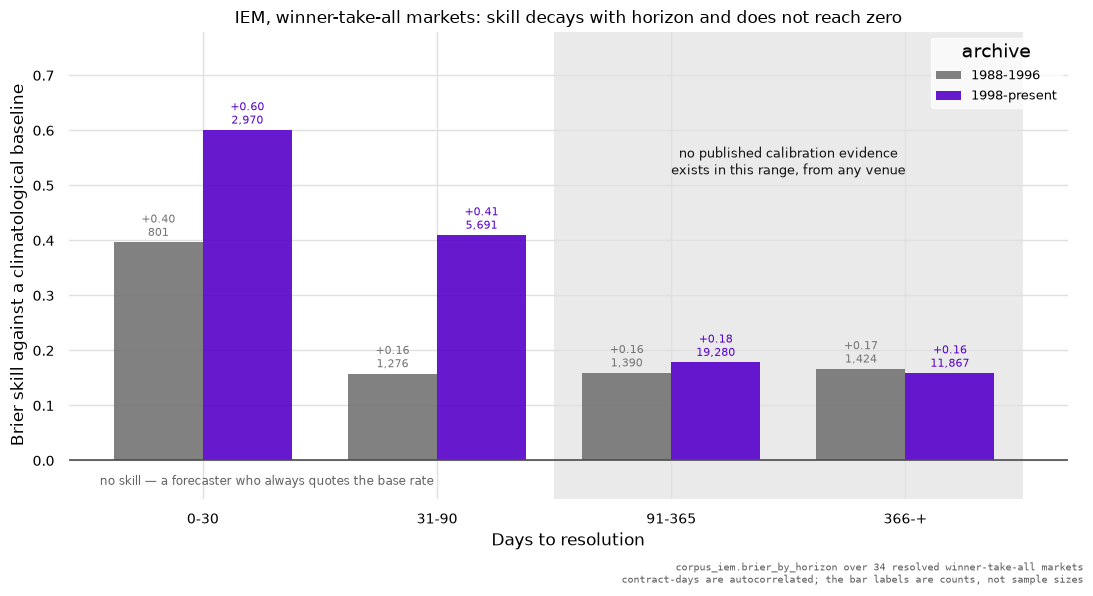

In [25]:
figure, axis = pyplot.subplots(figsize=(11, 6))
axis.set_axisbelow(True)

labels = [band_label(r) for r in pooled]
positions = numpy.arange(len(labels), dtype=float)
WIDTH = 0.38
for offset, (archive, source) in zip((-WIDTH / 2, WIDTH / 2), BY_ARCHIVE.items()):
    subset = [r for r in records if r["archive"] == archive]
    rows = {band_label(r): r for r in corpus_iem.brier_by_horizon(subset, source)}
    heights = [rows[label]["skill"] if label in rows else numpy.nan for label in labels]
    counts = [rows[label]["n_contract_days"] if label in rows else 0 for label in labels]
    colour = GREY if archive == "1988-1996" else IEM
    axis.bar(positions + offset, heights, WIDTH, color=colour, alpha=0.9, label=archive)
    for x, height, n in zip(positions + offset, heights, counts):
        axis.annotate(f"{height:+.2f}\n{n:,}", (x, height + 0.012), ha="center",
                      fontsize=8, color=colour)

axis.axhline(0, color="0.3", lw=1.2, zorder=1)
# Below the baseline rather than above it: every bar starts at zero, so any note
# placed inside the plot floor is written over the tallest thing on the page.
axis.text(-0.44, -0.038, "no skill — a forecaster who always quotes the base rate",
          fontsize=8.5, alpha=0.95, color="0.35", va="center")
axis.axvspan(1.5, len(labels) - 0.5, color="0.55", alpha=0.18, lw=0, zorder=0)
axis.text(2.5, 0.52, "no published calibration evidence\nexists in this range, from any venue",
          ha="center", fontsize=9.5, alpha=0.92)
axis.set_xticks(positions)
axis.set_xticklabels(labels)
axis.set_ylim(-0.07, 0.78)
axis.set_xlabel("Days to resolution")
axis.set_ylabel("Brier skill against a climatological baseline")
axis.set_title("IEM, winner-take-all markets: skill decays with horizon and does not "
               "reach zero", fontsize=12)
axis.legend(loc="upper right", fontsize=9, title="archive")
figure.tight_layout()
stamp_source("corpus_iem.brier_by_horizon over 34 resolved winner-take-all markets",
             "contract-days are autocorrelated; the bar labels are counts, not sample sizes",
             figure=figure)

Two readings, and the second is the one that is worth something.

Skill **decays monotonically with horizon**, 0.56 at a month to 0.16 beyond a
year in the pooled corpus, which is the same shape the published one-month
literature reports and is unsurprising. But it **does not decay to zero**: both
archives land near +0.16 beyond a year to resolution, thirty years apart, on
different questions. That is direct evidence on the question no published study
answers — long-dated real-money political markets were meaningfully better than a
climatological baseline, at a horizon where nothing has been measured before.

What it is not is a large or a safe number. The usable market count is 34, the
contract-days inside each band are autocorrelated to an unquantified degree, and
the sensitivity warning above is not hypothetical: this figure has already moved
once, from negative to positive, when the market set changed. Anything built on
it should recompute rather than cite.

## 12. Longshot bias, measured here rather than quoted

Now the measurement PredictIt could not support. The published Polymarket figure
is −19.3¢ per dollar below 10¢; the right way to use it is to check it against
another corpus, and IEM's is the one corpus in this study with resolved outcomes
and **no trading commission at all** — so whatever it shows is a property of the
traders rather than of a fee schedule.

The unit is cents per dollar staked: buy at `p`, receive $1 with realized
frequency `q`, and the return per dollar is `q/p − 1`. The first table below
computes it over contract-days, which is what the literature does. The second
table computes it over *contracts*, one unit each, which is what the
autocorrelation warning says to do. **They disagree, and the reason they
disagree is the finding.**

In [26]:
def forecast_rows(records: Sequence[dict[str, Any]],
                  rows_by_market: dict[str, list[dict[str, Any]]],
                  min_separation: float = 0.5) -> list[tuple[str, str, int, float, float]]:
    """(market, contract, days_to_resolution, price, outcome) for usable contract-days.

    The same selection as `corpus_iem._forecast_days` -- winner-take-all only,
    clean terminal separation only, settlement day dropped -- but keeping the
    market and contract identity, which is what the concentration check needs.
    """
    out: list[tuple[str, str, int, float, float]] = []
    for record in records:
        if record["settlement"] != "winner_take_all":
            continue
        if (record["label"].get("separation") or 0.0) <= min_separation:
            continue
        winner = record["label"]["winner"]
        terminal = date.fromisoformat(record["last_date"])
        for row in rows_by_market.get(record["market"], ()):
            price = row.get("last")
            if price is None or not (0.0 <= price <= 1.0):
                continue
            horizon = (terminal - date.fromisoformat(row["date"])).days
            if horizon <= 0:
                continue
            out.append((record["market"], row["contract"], horizon, price,
                        1.0 if row["contract"] == winner else 0.0))
    return out


FORECASTS = forecast_rows(records, ALL_ROWS)
BANDS = ((0.00, 0.02), (0.02, 0.05), (0.05, 0.10), (0.10, 0.20), (0.20, 0.40),
         (0.40, 0.60), (0.60, 0.80), (0.80, 0.90), (0.90, 1.0001))

print(f"over contract-days -- {len(FORECASTS):,} of them, from "
      f"{len({m for m, *_ in FORECASTS})} markets and "
      f"{len({(m, c) for m, c, *_ in FORECASTS})} contracts\n")
print(f"{'price band':14} {'days':>7} {'mean p':>8} {'realized':>9} {'gap':>8} {'cents/$':>9}")
for lo, hi in BANDS:
    sel = [(p, y) for _, _, _, p, y in FORECASTS if lo <= p < hi]
    if not sel:
        continue
    mean_p = sum(p for p, _ in sel) / len(sel)
    realized = sum(y for _, y in sel) / len(sel)
    cents = 100 * (realized / mean_p - 1) if mean_p > 0 else float("nan")
    print(f"[{lo:.2f},{hi:.2f})  {len(sel):>7,} {mean_p:>8.4f} {realized:>9.4f} "
          f"{realized - mean_p:>+8.4f} {cents:>+9.1f}")

print("\nThat bottom row says cheap IEM contracts paid a thousand cents per dollar staked, "
      "which is not a measurement of anything. It is one event counted many times.")

over contract-days -- 44,699 of them, from 34 markets and 137 contracts

price band        days   mean p  realized      gap   cents/$
[0.00,0.02)    8,536   0.0043    0.0501  +0.0458   +1068.0
[0.02,0.05)    3,032   0.0332    0.0313  -0.0019      -5.7
[0.05,0.10)    3,926   0.0704    0.1477  +0.0773    +109.8
[0.10,0.20)    5,500   0.1487    0.1769  +0.0282     +19.0
[0.20,0.40)    9,356   0.2959    0.2056  -0.0903     -30.5
[0.40,0.60)    8,713   0.4903    0.3787  -0.1115     -22.7
[0.60,0.80)    3,670   0.6725    0.7117  +0.0393      +5.8
[0.80,0.90)      838   0.8479    0.6516  -0.1963     -23.2
[0.90,1.00)    1,128   0.9590    0.8918  -0.0671      -7.0

That bottom row says cheap IEM contracts paid a thousand cents per dollar staked, which is not a measurement of anything. It is one event counted many times.


In [27]:
sub_two = [(m, c) for m, c, _, p, y in FORECASTS if p < 0.02 and y == 1.0]
print(f"winning contract-days priced under 2 cents: {len(sub_two)}")
print(f"{'market':22} {'contract':14} {'days':>5}  which election")
ELECTION = {"fr22r2_wta": "2022 French presidential, round 2",
            "fr22_cand": "2022 French presidential, runoff pairing",
            "fr22r1_wta": "2022 French presidential, round 1"}
top = Counter(sub_two).most_common(6)
for (market, contract), n in top:
    print(f"{market:22} {contract:14} {n:>5}  {ELECTION.get(market, '')}")
french = sum(n for (market, _), n in Counter(sub_two).items()
             if market in ELECTION)
print(f"\n{french} of {len(sub_two)} ({100 * french / len(sub_two):.0f}%) come from three "
      "contracts in the same election -- the 2022 French presidential round-2 pairing, which "
      "traded under two cents for 240 consecutive days and then happened.")
print("One event, counted 351 times. That is the autocorrelation warning made concrete: the "
      "contract-day table above is not measuring a population of longshots, it is measuring "
      "the 2022 French election with a very heavy weight.")

print(f"\nover contracts instead -- one unit each, its mean price against its outcome\n")
per_contract: dict[tuple[str, str], list[tuple[float, float]]] = defaultdict(list)
for market, contract, _, price, outcome in FORECASTS:
    per_contract[(market, contract)].append((price, outcome))
units = [(sum(p for p, _ in v) / len(v), v[0][1]) for v in per_contract.values()]

COARSE = ((0.00, 0.05), (0.05, 0.15), (0.15, 0.35), (0.35, 0.65), (0.65, 0.85), (0.85, 1.0001))
print(f"{'price band':14} {'contracts':>10} {'mean p':>8} {'won':>4} {'realized':>9} "
      f"{'gap':>8} {'cents/$':>9}")
for lo, hi in COARSE:
    sel = [(p, y) for p, y in units if lo <= p < hi]
    if not sel:
        continue
    mean_p = sum(p for p, _ in sel) / len(sel)
    won = int(sum(y for _, y in sel))
    realized = won / len(sel)
    cents = 100 * (realized / mean_p - 1) if mean_p > 0 else float("nan")
    print(f"[{lo:.2f},{hi:.2f})  {len(sel):>10} {mean_p:>8.4f} {won:>4} {realized:>9.4f} "
          f"{realized - mean_p:>+8.4f} {cents:>+9.1f}")
print(f"{'total':14} {len(units):>10}")
print("\nForty contracts under five cents, of which one won. Twenty-two between five and "
      "fifteen, of which one won. At those counts the standard error on the realized "
      "frequency is larger than the effect the literature reports, so this corpus cannot "
      "confirm or refute -19.3 cents per dollar. It is too small, and that is the answer.")
print("\nWhat the middle of the table does show, consistently across four bands, is a "
      "negative gap: contracts priced 0.15 to 0.85 realized less often than their price, "
      "and the top band realized more. That is compression toward the middle -- the same "
      "shape as a calibration slope above one -- and it is the wedge the literature calls "
      "a structural property of political prediction markets rather than a venue artefact.")

winning contract-days priced under 2 cents: 428
market                 contract        days  which election
fr22r2_wta             R2_MacDLeP       240  2022 French presidential, round 2
fr22_cand              R_MacxUnn         92  2022 French presidential, runoff pairing
fr22r1_wta             R1Runoff          19  2022 French presidential, round 1
house18                RH.lose18          9  
congress18             DH_RS18            8  
pres00_wta             Dem                7  

351 of 428 (82%) come from three contracts in the same election -- the 2022 French presidential round-2 pairing, which traded under two cents for 240 consecutive days and then happened.
One event, counted 351 times. That is the autocorrelation warning made concrete: the contract-day table above is not measuring a population of longshots, it is measuring the 2022 French election with a very heavy weight.

over contracts instead -- one unit each, its mean price against its outcome

price band      contract

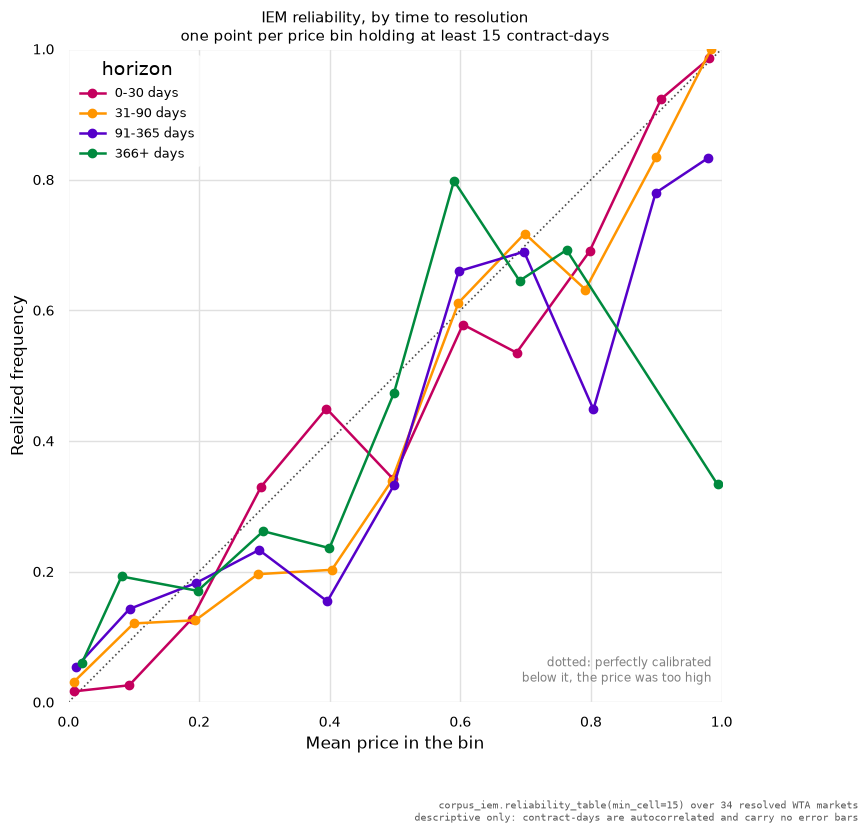

In [28]:
reliability = corpus_iem.reliability_table(records, ALL_ROWS, min_cell=15)
BAND_COLOUR = {(0, 30): "#C4005E", (31, 90): "#FF9500", (91, 365): IEM, (366, None): "#008A3E"}

figure, axis = pyplot.subplots(figsize=(9.5, 8.4))
axis.set_axisbelow(True)
axis.plot([0, 1], [0, 1], color="0.3", lw=1.2, ls=":", zorder=1)
# The reference line named in the corner rather than written along itself, which
# on a curve-crowded diagonal collides with every series at once.
axis.text(0.985, 0.025, "dotted: perfectly calibrated\nbelow it, the price was too high",
          transform=axis.transAxes, ha="right", va="bottom", fontsize=8.5, alpha=0.9,
          color=GREY)

for (lo, hi), colour in BAND_COLOUR.items():
    cells = [c for c in reliability if c["horizon_lo"] == lo]
    if not cells:
        continue
    label = f"{lo}-{hi} days" if hi else f"{lo}+ days"
    axis.plot([c["mean_price"] for c in cells], [c["realized"] for c in cells],
              color=colour, lw=1.8, marker="o", markersize=6, label=label, zorder=3)

axis.set_xlim(0, 1)
axis.set_ylim(0, 1)
axis.set_aspect("equal")
axis.set_xlabel("Mean price in the bin")
axis.set_ylabel("Realized frequency")
axis.set_title("IEM reliability, by time to resolution\n"
               "one point per price bin holding at least 15 contract-days", fontsize=11)
axis.legend(loc="upper left", fontsize=9, title="horizon")
figure.tight_layout()
stamp_source("corpus_iem.reliability_table(min_cell=15) over 34 resolved WTA markets",
             "descriptive only: contract-days are autocorrelated and carry no error bars",
             figure=figure)

Read the shape rather than the points. Three of the four curves sit **below the
diagonal through the middle of the range** and cross above it at both ends,
which is the compression the tables just measured: prices between roughly 0.2
and 0.8 realized less often than they promised. The 366+ curve is the loosest
and swings hardest, which is what a small sample at long horizon looks like and
not necessarily what the market was doing.

Nothing here carries an error bar, and that is deliberate rather than an
omission. A contract-day is not an independent observation — the previous
section showed a single French contract supplying 240 of them — so an interval
computed as though they were would be far too narrow and would lend the picture
an authority it has not got.

## 13. Exclusive-set coherence, on sixteen years with no fee

The research pass called exclusive-set coherence **the strongest single quality
test** available: if a set of outcomes is exhaustive and mutually exclusive,
their prices must sum to one, discounted for the time until settlement. On
Polymarket it catches non-exhaustive candidate fields, stale midpoints and
broken books in one shot — and on 255 exclusive political events only **45% sat
within ±2% of 1.0**, with 61% of sets beyond a year more than 5% away.

IEM has a market that tests this about as cleanly as it can be tested. The
**Federal Reserve Monetary Policy Market B** ran from October 2001 to December
2017 and listed, for each FOMC meeting, an exclusive triple: the target rate goes
up, stays the same, or goes down. 302 contracts, 29,308 daily rows, and — because
IEM charges no trading commission — a sum that deviates from one for only two
reasons rather than three: the spread, and the cost of capital locked until the
meeting.

It is also a **macro** market that settles on a published central-bank decision,
which is the architecture that makes Kalshi worth building for macro. IEM was
doing it in 2001.

In [29]:
FED = modern_rows["fedpolicyb"]
LEG = re.compile(r"^FR(up|same|down)(\d{2})(\d{2})$")

triples: dict[tuple[str, str, str], dict[str, float]] = defaultdict(dict)
for row in FED:
    match = LEG.match(row["contract"] or "")
    if match is None or row.get("last") is None:
        continue
    leg, month, year = match.groups()
    triples[(row["date"], month, year)][leg] = row["last"]

complete = {k: v for k, v in triples.items() if len(v) == 3}
# A cell where all three legs sit at the 0.001 floor is a contract not yet open
# or already settled, not a priced triple. Excluded and counted rather than
# silently averaged in, exactly as the research pass treated Polymarket's
# placeholder outcomes.
live = {k: v for k, v in complete.items() if sum(v.values()) > 0.5}
dead = len(complete) - len(live)

print(f"{'FEDERAL RESERVE MONETARY POLICY MARKET B'}")
dates = sorted({r['date'] for r in FED})
print(f"  {dates[0]} .. {dates[-1]},  {len({r['contract'] for r in FED})} contracts, "
      f"{len(FED):,} daily rows")
print(f"  date x meeting cells with all three legs quoted: {len(complete):,}")
print(f"  of which priced (sum > 0.5): {len(live):,};  unopened or settled: {dead:,}\n")

sums = sorted(sum(v.values()) for v in live.values())
print(f"{'quantile':>10} {'sum of the exclusive triple':>28}")
for q in (0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99):
    print(f"{q:>10.0%} {sums[int(q * (len(sums) - 1))]:>28.4f}")
print(f"{'mean':>10} {statistics.mean(sums):>28.4f}")

print(f"\n{'tolerance':>12} {'IEM, 2001-2017':>16} {'Polymarket, 2026 (published)':>30}")
PUBLISHED = {0.02: "45% of 255 exclusive political events", 0.05: "61% of sets beyond a year "
             "were MORE than 5% away"}
for tolerance in (0.01, 0.02, 0.05, 0.10):
    share = sum(1 for s in sums if abs(s - 1) <= tolerance) / len(sums)
    print(f"{f'+-{tolerance:.2f}':>12} {share:>15.1%}  {PUBLISHED.get(tolerance, ''):>30}")

within_two = sum(1 for s in sums if abs(s - 1) <= 0.02) / len(sums)
print(f"\nSo the tiny fee-free university market is more internally coherent on the single "
      f"strongest structural test than the billion-dollar venue -- {within_two:.0%} within two "
      "points against 45%. The comparison is suggestive rather than like-for-like: different "
      "question sets, different horizons, a three-leg set against fields of up to 121 "
      "outcomes, sixteen years pooled against one day, and a published figure against a "
      "computed one. What it does rule out is the idea that coherence follows size.")
print(f"\nAnd the deviations are not symmetric: the median sits at "
      f"{statistics.median(sums):.4f} and the 95th percentile at "
      f"{sums[int(0.95 * (len(sums) - 1))]:.4f}, so the tail is overround rather than "
      "discount -- sets costing more than a dollar, not less. A capital lock-up discount "
      "would pull the sum below one; whatever is happening in that tail is the spread and "
      "stale legs, not the cost of money.")

FEDERAL RESERVE MONETARY POLICY MARKET B
  2001-10-03 .. 2017-12-15,  302 contracts, 29,308 daily rows
  date x meeting cells with all three legs quoted: 7,818
  of which priced (sum > 0.5): 7,116;  unopened or settled: 702

  quantile  sum of the exclusive triple
        1%                       0.7910
        5%                       0.9430
       25%                       0.9990
       50%                       1.0030
       75%                       1.0180
       95%                       1.1010
       99%                       1.2800
      mean                       1.0120

   tolerance   IEM, 2001-2017   Polymarket, 2026 (published)
      +-0.01           52.7%                                
      +-0.02           66.3%  45% of 255 exclusive political events
      +-0.05           82.5%  61% of sets beyond a year were MORE than 5% away
      +-0.10           91.3%                                

So the tiny fee-free university market is more internally coherent on the single st

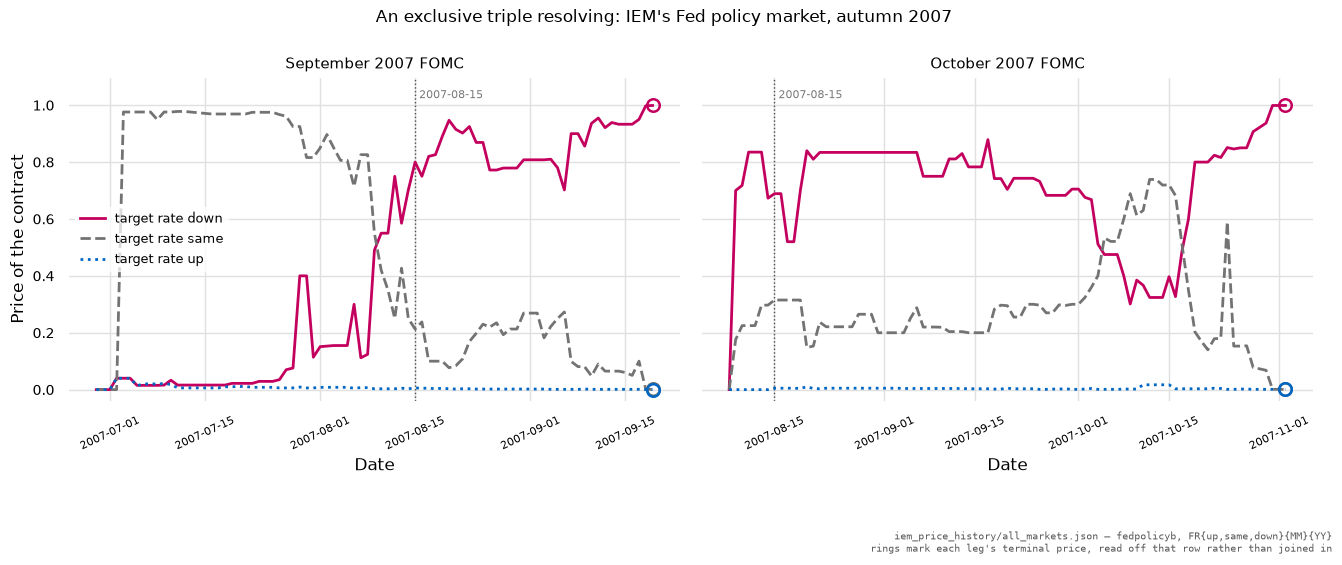

In [30]:
# One meeting pair, from quote to settlement, so the label can be read off the
# data rather than asserted from outside. The terminal row of each contract *is*
# its settlement: IEM liquidates at the outcome and the last price is that value.
MEETINGS = (("09", "07", "September 2007 FOMC"), ("10", "07", "October 2007 FOMC"))
LEG_STYLE = {"down": ("#C4005E", "-"), "same": (GREY, "--"), "up": (POLYMARKET, ":")}
#: A date on which both meetings were live, so the two triples can be read as a
#: term structure rather than as two unrelated markets. Chosen for that reason
#: and stated rather than searched for, so the reading is reproducible.
ASOF = "2007-08-15"

figure, axes = pyplot.subplots(1, 2, figsize=(13.5, 5.6), sharey=True)
for axis, (month, year, title) in zip(axes, MEETINGS):
    axis.set_axisbelow(True)
    for leg, (colour, style) in LEG_STYLE.items():
        series = sorted((row["date"], row["last"]) for row in FED
                        if row["contract"] == f"FR{leg}{month}{year}" and row.get("last") is not None)
        if not series:
            continue
        # Datetimes go to plot() so matplotlib formats the axis as dates; date2num
        # is for the scalar axis arguments below, whose stubs type them as floats.
        moments = [datetime.fromisoformat(d) for d, _ in series]
        axis.plot(moments, [v for _, v in series], color=colour, ls=style, lw=2.0,
                  label=f"target rate {leg}")
        axis.plot(moments[-1:], [series[-1][1]], marker="o", markersize=9,
                  mfc="none", mew=1.8, color=colour, zorder=4)
    # The date this section reads the term structure on, marked on both panels.
    axis.axvline(date2num(datetime.fromisoformat(ASOF)), color="0.3", lw=1, ls=":", zorder=1)
    axis.text(date2num(datetime.fromisoformat(ASOF)), 0.96, f" {ASOF}",
              transform=axis.get_xaxis_transform(), fontsize=8, alpha=0.95, color=GREY,
              va="top")
    axis.set_ylim(-0.04, 1.10)
    axis.set_title(title, fontsize=11)
    axis.set_xlabel("Date")
    axis.tick_params(axis="x", labelrotation=25, labelsize=8)
axes[0].set_ylabel("Price of the contract")
axes[0].legend(loc="center left", fontsize=9)

figure.suptitle("An exclusive triple resolving: IEM's Fed policy market, autumn 2007",
                fontsize=12)
figure.tight_layout()
stamp_source("iem_price_history/all_markets.json — fedpolicyb, FR{up,same,down}{MM}{YY}",
             "rings mark each leg's terminal price, read off that row rather than joined in",
             figure=figure)
# tight_layout has already placed the axes; stamp_source only reserves room at
# the bottom, and the rotated date labels here need more of it than its default.
figure.subplots_adjust(bottom=0.28)

In [31]:
print(f"{'meeting':22} {'days quoted':>11} {'from':>12} {'to':>12} "
      f"{'terminal down/same/up':>24}")
for month, year, title in MEETINGS:
    legs = {leg: sorted((row["date"], row["last"]) for row in FED
                        if row["contract"] == f"FR{leg}{month}{year}"
                        and row.get("last") is not None)
            for leg in ("down", "same", "up")}
    first = min(series[0][0] for series in legs.values())
    last = max(series[-1][0] for series in legs.values())
    terminal = "/".join(f"{legs[leg][-1][1]:.3f}" for leg in ("down", "same", "up"))
    print(f"{title:22} {len(legs['down']):>11} {first:>12} {last:>12} {terminal:>24}")
    # The quote on ASOF: the last observation at or before it, which is what a
    # reader on that day would have seen.
    asof_quote = {leg: next((v for d, v in reversed(series) if d <= ASOF), None)
                  for leg, series in legs.items()}
    horizon = (date.fromisoformat(last) - date.fromisoformat(ASOF)).days
    if all(v is not None for v in asof_quote.values()):
        print(f"{'':22} on {ASOF}, {horizon:>3} days before settlement:  "
              + "  ".join(f"{leg} {asof_quote[leg]:.3f}" for leg in ("down", "same", "up"))
              + f"   sum {sum(asof_quote.values()):.3f}")
    else:
        print(f"{'':22} not yet quoted on {ASOF}")

print(f"\nBoth meetings settled 'down'. Read the two {ASOF} lines as a term structure: on one")
print("day the market held a coherent view of two successive meetings, right on the")
print("direction of both, 35 and 79 days out, and underconfident on both. Underconfident")
print("in exactly the direction the reliability curve in section 12 shows from the other")
print("side -- compression toward the middle -- and here on a macro question rather than an")
print("election, settling on a published central-bank decision rather than on reporting.")
print("\nThe settlement is read off the file: the terminal price of the winning leg is 0.999")
print("and the losing legs 0.000-0.001. Nothing was joined to an external record of FOMC")
print("decisions, which is the discipline corpus_iem.terminal_label exists to keep -- and it")
print("is what makes this archive usable for method development at all.")

meeting                days quoted         from           to    terminal down/same/up
September 2007 FOMC             80   2007-06-29   2007-09-19        0.999/0.001/0.000
                       on 2007-08-15,  35 days before settlement:  down 0.800  same 0.213  up 0.006   sum 1.019
October 2007 FOMC               86   2007-08-08   2007-11-02        0.999/0.001/0.001
                       on 2007-08-15,  79 days before settlement:  down 0.689  same 0.315  up 0.005   sum 1.009

Both meetings settled 'down'. Read the two 2007-08-15 lines as a term structure: on one
day the market held a coherent view of two successive meetings, right on the
direction of both, 35 and 79 days out, and underconfident on both. Underconfident
in exactly the direction the reliability curve in section 12 shows from the other
side -- compression toward the middle -- and here on a macro question rather than an
election, settling on a published central-bank decision rather than on reporting.

The settlement is re

## 14. What IEM's size costs

Everything above is available because IEM is small and academic. The same fact
is what it cannot do, and the list is short and absolute.

**No order book, ever** — not live, not historical, one file excepted. Every
depth and sweep metric in the catalogue is unavailable; the daily low-to-high
range is the only spread proxy, and it is weak.

**No monitoring.** Three open markets. A watchlist is not a thing that can exist
here.

**Tiny stakes, by design.** A trading account is capped at $500. So IEM answers
"were these prices well calibrated" and can never answer "could I have traded on
it" — and that cap is also why it survived as a research market for
thirty-eight years while everything larger drew a regulator.

**No guarantee of a future.** It is a university project, not a business, and
the 1988–1996 index is already broken in the way section 9 describes.

In [32]:
print(f"{'metric family':46} {'IEM':>9}  note")
for name, row in metrics.VENUE_COVERAGE.items():
    verdict, note = row["iem"]
    if verdict in {"no", "partial"}:
        print(f"{name[:46]:46} {verdict:>9}  {textwrap.shorten(note, 66)}")

iem_tally = Counter(row["iem"][0] for row in metrics.VENUE_COVERAGE.values())
print(f"\nIEM across {len(metrics.VENUE_COVERAGE)} families: "
      + ", ".join(f"{n} {k}" for k, n in sorted(iem_tally.items())))
print(f"PredictIt, for comparison:      "
      + ", ".join(f"{n} {k}" for k, n in sorted(tally.items())))

#: What each small venue has that neither large one does. Stated as data so the
#: closing section argues from a list rather than from memory.
UNIQUE_TO: dict[str, tuple[str, ...]] = {
    "predictit": (
        "the whole venue in one unauthenticated GET -- no pagination, no tag registry",
        "a rate limit published in response headers rather than discovered by probing",
        "a fee schedule whose wedge is exact arithmetic instead of an estimated bias",
        "a contract list chosen by a board of academics on staggered terms",
        "an investment cap set by statute (FECA-indexed) and stated per contract",
    ),
    "iem": (
        "daily per-contract prices for every market it has run, back to 1988-06-01",
        "no trading commission at all, so a measured bias is not a fee artefact",
        "share volume AND dollar volume per contract per day, checkable",
        "a bid and an ask -- in exactly one market, the 1988 presidential file",
        "resolved outcomes readable off the terminal row, with no external join",
    ),
}
for venue, items in UNIQUE_TO.items():
    print(f"\nonly on {venue}:")
    for item in items:
        print(f"  - {item}")

metric family                                        IEM  note
depth_within_1c / depth_within_5c                     no  No book is published, live or historical.
absolute_spread / relative_spread                partial  Daily low/high only; the intraday spread is not recoverable.
midpoint_vs_last_trade_divergence                partial  Daily last against the day's low/high midpoint only.
open_interest                                         no  Not published.
volume_to_open_interest_turnover                      no  Volume yes, open interest no.
holder_count / holder_concentration                   no  Not served.
time_since_last_trade                            partial  Zero-volume days are visible, so 'no trade today' is [...]
quote_age                                             no  No book.
resolution_text_length / named_source            partial  Prospectus is a static .txt per market, so length and [...]
dispute_history                                       no  Not served.

IEM

## 15. Where each of these belongs, if anywhere

**PredictIt: a snapshot recorder, and a second opinion that costs one request a
day.** The whole venue is one GET, so the marginal cost of keeping it is
negligible and the thing it accumulates — a dated series of US political
contract prices with a per-day close that reconciles against the chart endpoint —
is not obtainable any other way and is not recoverable later. If it is going to
be wanted in 2028 it has to start now. That is the argument for the recorder and
it is the only argument that does not depend on the prices being good.

What it cannot be is the price you quote. The fee band alone pins a probability
to ±2.6 points at the middle of the range before any spread, and the median
touch spread adds three cents on top of that. The spread is the larger of the
two on most contracts and would narrow with more participants; the fee band
would not, because it is charged on the trade rather than quoted in the book. So
there is a floor of a couple of points under every PredictIt price that no
amount of liquidity removes. Nor can the price be traded at size: $3,500 per
contract, indexed, and no published depth at all to say whether even that is
reachable.

Where it might earn its place is as a **disagreement detector** across venues. A
PredictIt price and a Kalshi price on the same question differ for three
reasons — different fee wedges, different participant pools, different resolution
texts — and the first of those is computable to four decimal places from the
schedule. A divergence wider than the union of the two fee bands is therefore a
real disagreement about the world rather than an artefact of costs, and that is
a measurable object. Whether it is a *useful* one is a cross-venue question and
belongs in [`calibration.ipynb`](calibration.ipynb), not here.

**IEM: a method bench, and nothing else.** Three open markets and a $500 account
cap settle the question of whether it is a live signal. But the archive is the
only place in this study where a calibration method can be developed against
known answers, on a static file, with no fee to model and no vendor to change
the API underneath it — and where the answer can be checked at horizons nobody
has published. Section 11's result is the kind of thing that can only come from
here: skill decaying from 0.56 to 0.16 across horizon bands and stopping well
above zero past a year, on two archives thirty years apart.

The discipline to take from it is the two corrections in section 10. A price
that is not on a $1 scale, and a settlement that is a continuous share rather
than a binary, are both errors that leave the numbers looking entirely
plausible. Both exist on the modern venues too — Polymarket's cumulative date
ladders legitimately sum to 6.77 and a naive coherence check flags them as
broken — and IEM is the cheap place to learn to catch them.

**For the trading question that motivates all of this, neither is an input.**
Pairs trading needs an executable price and a hedge, and these two venues supply
neither: one caps a participant at $3,500 per contract and publishes no depth,
the other caps an account at $500 and has three open markets. What they supply
is evidence about whether prices of this kind are worth reading at all — which
is a prior question, and the one this notebook is about. The venues where the
question becomes a position are the two large ones, and the wedges this notebook
computed in arithmetic have to be *measured* there instead.

One thing the two of them share, and it is the reason to keep both. Both are
academic instruments before they are exchanges — PredictIt's contract list is
chosen by a board of academics on staggered terms, IEM has run inside a
university since 1988 under relief granted for research and teaching — and
almost every quantity in this notebook exists because of that. A rate limit
published in a response header. A fee schedule stated plainly enough to be
arithmetic. A regulator's letter explaining, on the record, why a cap had
distorted the data it was collecting. A per-day price file that has not changed
since 1996.

The large venues are better markets. On the places where this notebook could
check a number, these two could be checked and, more often than not, the large
ones could not: volume that cannot be audited, a `liquidity` field that means
something other than liquidity, an editable resolution text with no archive of
what it used to say. That is not an argument for trading here. It is an argument
for measuring here, and for being careful about what a price from anywhere else
is actually telling you.